### **INFORME TÉCNICO: CLASIFICACIÓN DE PAISAJES MEDIANTE REDES NEURONALES CONVOLUCIONALES (CNN)**

**Integrantes:** Christian Pastran, Alessandro Rosell, Diego Mancilla

**Seccion**: 001D

### **INTRODUCCION**

1. **Definicion para el Problema del Negocio, Objetivos a buscar y Metricas esperadas en nuestro contexto**:

**1.1** **Introduccion al problema del negocio**: En la actualidad, las plataformas digitales de turismo, agencias de viajes y bancos de imágenes gestionan millones de archivos fotográficos que requieren ser catalogados de forma precisa. La clasificación manual de estos recursos visuales resulta ineficiente, costosa y propensa a errores humanos. **¿Porque es necesario resolver esto?** Porque ayudaria mucho a problemas criticos de eficiencia, costos y organizacion de contenido debido a las cantidad lugares turisticos que podria estar manejando esta misma empresa.

**1.2** Nuestro proyecto busca abordar esta problemática mediante el desarrollo de un modelo de Visión por Computadora basado en Redes Neuronales Convolucionales (CNN). El sistema automatiza el etiquetado y categorización de imágenes extrayendo caracteristicas cruciales utilizando estas capas convolucionales pare despues pasarlo a un modelo **MLP** que utilice la informacion extraida de paisajes, ciudades, playas, etc. Optimizando el motor de búsqueda y recomendación para la busqueda de informacion, minimizando los errores de etiquetado en la plataforma.



**1.3 Objetivos Específicos**

Configurar una variante propia y acotada del dataset para garantizar la reproducibilidad y el balance de clases.

Diseñar e implementar una arquitectura de CNN que extraiga patrones visuales clave (bordes, texturas, colores) de los diferentes paisajes.

Evaluar el rendimiento del modelo mediante métricas de clasificación estándar ($Accuracy$, $Precision$, $Recall$, $F1\text{-Score}$ y Matriz de Confusión).

**1.4 Definición de KPIs y Metas Deseadas**

Para considerar el modelo apto para su despliegue en un entorno de producción (catálogo digital/app de turismo), se establecen los siguientes indicadores clave de rendimiento (KPIs):

-------------------------------------

**Recall Promedio**: >= 85%

  En un catálogo fotográfico o app de turismo, el costo de perder o traspapelar una foto (Falso Negativo) es alto. Queremos asegurar que el modelo identifique correctamente al menos el $85\%$ del total de imágenes reales de cada categoría de paisaje.

**Precision Global**: >= 80%

Mantiene un nivel de exactitud aceptable para evitar que se mezclen demasiadas fotos irrelevantes en las galerías mostradas a los usuarios.

**F1-Score Ponderado**: >= 0.82

Valida el equilibrio global entre el Recall alcanzado y la precisión en todas las clases.



**EXTRACCION DE ARCHIVOS**

En esta parte del trabajo creamos las carpetas necesarias para la extraccion de los archivos del dataset **raw** para el dataset completo sin ningun tipo de cambios en los archivos **processed** para los archivos ya procesados y adaptados a las necesidades del trabajo

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Model
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix)

import os
import shutil
import subprocess
from pathlib import Path

# Definir rutas raíz compatibles con Google Colab de forma determinista
project_root = Path("/content")

# Crear únicamente las carpetas del proyecto que todavía no existen
directories = ["data/raw", "data/processed", "models", "images"]
for directory in directories:
    directory_path = project_root / directory
    if directory_path.exists():
        print(f"La carpeta ya existe: {directory_path}")
    else:
        directory_path.mkdir(parents=True, exist_ok=True)
        print(f"Carpeta creada: {directory_path}")

# Configurar las rutas del archivo ZIP y destino de extracción
zip_path = project_root / "data" / "raw" / "Intel_Image_Classification.zip"
extract_path = project_root / "data" / "raw" / "extracted"

if not zip_path.is_file():
    raise FileNotFoundError(f"No se encontró el archivo ZIP en la ruta: {zip_path}. Asegúrate de subirlo primero.")

# Crear la carpeta destino de extracción si no existe
extract_path.mkdir(parents=True, exist_ok=True)

# Para garantizar la máxima estabilidad y velocidad en Colab sin errores de 'OSError: [Errno 22]',
# usamos la utilidad nativa de descompresión del sistema mediante subprocess.
# Esto es 100% reproducible y seguro de ejecutar múltiples veces.
print(f"Comprobando estado de extracción en: {extract_path}...")

# Verificamos si ya existen carpetas clave dentro del destino para no repetir el proceso si no es necesario
significant_dir = extract_path / "seg_train"
if significant_dir.is_dir():
    print("El dataset ya se encuentra extraído correctamente. Omitiendo extracción para optimizar tiempo.")
else:
    print("Iniciando extracción mediante herramienta nativa del sistema...")
    try:
        # -q ejecuta de forma silenciosa, -n evita sobrescribir archivos que ya existen de ejecuciones previas
        resultado = subprocess.run(
            ["unzip", "-n", "-q", str(zip_path), "-d", str(extract_path)],
            check=True,
            capture_output=True,
            text=True
        )
        print("Extracción completada correctamente de forma segura en Colab.")
    except subprocess.CalledProcessError as e:
        print(f"Error al extraer con unzip nativo: {e.stderr}")
        print("Intentando método alternativo mediante Python...")
        import zipfile
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(path=extract_path)
        print("Extracción con zipfile completada.")

La carpeta ya existe: /content/data/raw
La carpeta ya existe: /content/data/processed
La carpeta ya existe: /content/models
La carpeta ya existe: /content/images
Comprobando estado de extracción en: /content/data/raw/extracted...
El dataset ya se encuentra extraído correctamente. Omitiendo extracción para optimizar tiempo.


### **DESARROLLO**

**2.1 Definición de la Variante Propia del Dataset**

Con el propósito de cumplir con los requerimientos metodológicos de la evaluación y garantizar la reproducibilidad exacta de los experimentos, el grupo ha establecido la siguiente variante técnica personalizada:

**Subconjunto de Clases:** Se seleccionó un subconjunto de 4 clases representativas del total disponible en el dataset ['buildings', 'forest', 'sea', 'street'], permitiendo enfocar la capacidad del modelo en la discriminación de entornos naturales y urbanos de manera especifica específicos, permitiendo para el negocio poder reconcer la ubicacion de hoteles mas rapido para la empresa, y generar mejores propuestas de ubicaciones, precios y lugares de  interes.

**Límite de Muestras por Clase:** Se fijó un tope estricto de $2.000$ imágenes por clase para el conjunto de entrenamiento mediante un submuestreo aleatorio balanceado, optimizando la carga computacional en memoria tanto en CPU atravez del codespace y GPU para reprudictividad en entornos de google colab.

**Semilla Aleatoria de Reproducibilidad (Seed):** Se definió de manera global la semilla SEED = 42 para la partición de datos (Train/Test/Validation) e inicialización de pesos de la CNN, **¿Por que?**, esto garantiza que la simagenes seleccionadas sean exactamente las mismas cada vez que el codigo deba ser ejecutado.

In [ ]:
import os
import shutil
import random
import tensorflow as tf

CLASES_SELECCIONADAS = ['buildings', 'forest', 'sea', 'street']
LIMITE_IMAGENES_POR_CLASE = 2000
SEED = 42

random.seed(SEED)

# Rutas origen y destino relativas a la raíz real del proyecto
base_extracted = project_root / "data" / "raw" / "extracted"
train_orig = base_extracted / "seg_train" / "seg_train"
test_orig = base_extracted / "seg_test" / "seg_test"

# Carpeta procesada donde vivirá la variante del grupo
processed_dir = project_root / "data" / "processed" / "dataset_variante"
train_proc = processed_dir / "train"
test_proc = processed_dir / "test"

for source_dir in (train_orig, test_orig):
    if not source_dir.is_dir():
        raise FileNotFoundError(f"No se encontró la carpeta de origen: {source_dir}")

print(f"Train original: {train_orig}")
print(f"Test original: {test_orig}")
print(f"Train procesado: {train_proc}")
print(f"Test procesado: {test_proc}")

def crear_variante(origen, destino, limite=None):
    if os.path.exists(destino):
        shutil.rmtree(destino) # Limpia si ya existía para garantizar reproducibilidad

    for clase in CLASES_SELECCIONADAS:
        ruta_clase_origen = os.path.join(origen, clase)
        ruta_clase_destino = os.path.join(destino, clase)
        os.makedirs(ruta_clase_destino, exist_ok=True)

        imagenes = os.listdir(ruta_clase_origen)
        imagenes.sort() # Ordenar primero para que la semilla sea 100% determinista
        random.shuffle(imagenes)

        # Aplicar el límite por clase si se especifica
        if limite and len(imagenes) > limite:
            imagenes = imagenes[:limite]

        for img in imagenes:
            shutil.copy(
                os.path.join(ruta_clase_origen, img),
                os.path.join(ruta_clase_destino, img)
            )

print(f"Creando variante de {len(CLASES_SELECCIONADAS)} clases, con un máximo de {LIMITE_IMAGENES_POR_CLASE} imágenes por clase...")
crear_variante(train_orig, train_proc, limite=LIMITE_IMAGENES_POR_CLASE)
crear_variante(test_orig, test_proc, limite=None) # Test conserva todas las imágenes de las clases seleccionadas
print("¡Variante creada con éxito!")

Train original: /content/data/raw/extracted/seg_train/seg_train
Test original: /content/data/raw/extracted/seg_test/seg_test
Train procesado: /content/data/processed/dataset_variante/train
Test procesado: /content/data/processed/dataset_variante/test
Creando variante de 4 clases, con un máximo de 2000 imágenes por clase...
¡Variante creada con éxito!


**2.2 Carga y preparacion para el Flujo de los Datos**

Una vez ya creada la variante de la informacion del dataset que vamos a ocupar, pasamos al redimensionamiento de las imagenes, validaciones y preservacion del test para la evaluacion de metricas $Recall$, $Precision$, $F1\text{-Score}$.

**Redimensionamiento:** Cada pixel es una entrada de datos para nuestro modelo, decidimos ocupar **$64x64$** pixeles para asegurar un buen uso de los recursos para garantizar un aprendizaje mas fluido y menos tardio.

**Validation Split:** Principalmente decidimos ocupar unas **2000 imagenes** por clase, apartir de esto al tener un balanceo equitativo entre las fotos a analizar decidimos ocupar el ['validation split = 0.2'] para ocupar 800 imagenes que ocuparan las capas convolucionales y asi ajustar sus pesos para el entrenamiento, y el resto (**200 imagenes**) que guardara para evaluar si el modelo generaliza de manera correcta al final de cada una de las epocas (validacion).

Y por ultimo ocupariamos el **dataset_test** para evaluar las metricas antes mencionadas

In [ ]:
import tensorflow as tf
import os

TAMANO_IMAGEN = (64, 64)
TAMANO_BATCH = 32
SEED = 42

# El modelo usa la variante creada con el límite de imágenes y la seed definidos arriba
train_dir = train_proc
test_dir = test_proc
model_dir = project_root / "models"

# Verificación rápida antes de cargar
if not train_dir.is_dir():
    raise FileNotFoundError(
        f"No se encontró {train_dir}. Ejecuta primero la celda que crea la variante del dataset."
    )
if not test_dir.is_dir():
    raise FileNotFoundError(
        f"No se encontró {test_dir}. Ejecuta primero la celda que crea la variante del dataset."
    )

print(f"Directorio de entrenamiento: {train_dir}")
print(f"Directorio de prueba: {test_dir}")
print(f"Directorio para guardar el modelo: {model_dir}")
print("Clases de entrenamiento:", sorted(path.name for path in train_dir.iterdir() if path.is_dir()))

# 1. Carga de Train y Validation
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=TAMANO_IMAGEN,
    batch_size=TAMANO_BATCH,
    label_mode='categorical'
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=TAMANO_IMAGEN,
    batch_size=TAMANO_BATCH,
    label_mode='categorical'
)

# 2. Carga de Test
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=TAMANO_IMAGEN,
    batch_size=TAMANO_BATCH,
    label_mode='categorical',
    shuffle=False
)

nombre_clases = train_dataset.class_names
print("Clases encontradas en el dataset:", nombre_clases)
print("Número total de clases:", len(nombre_clases))

# 3. Optimización del pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Directorio de entrenamiento: /content/data/processed/dataset_variante/train
Directorio de prueba: /content/data/processed/dataset_variante/test
Directorio para guardar el modelo: /content/models
Clases de entrenamiento: ['buildings', 'forest', 'sea', 'street']
Found 8000 files belonging to 4 classes.
Using 6400 files for training.
Found 8000 files belonging to 4 classes.
Using 1600 files for validation.
Found 1922 files belonging to 4 classes.
Clases encontradas en el dataset: ['buildings', 'forest', 'sea', 'street']
Número total de clases: 4


**2.3 Analisis Exploratorio de Datos  EDA**

Se realizo un analisis exploratorio de datos en base a las clases que estaremos revisando que son **['buildings', 'forest', 'sea', 'street']**, y se lograron reconocer ciertos puntos en el cual el modelo pueda tener alguna tendencia a equivocarse o en este caso a confundir las diferentes clases:

**Clases que podria confundir con mayor frecuencia**

Las clases **street** y **buildings** serian de las 4 que escogimos las que el modelo podria confundir con mayor facilidad, debido que en street, las imagenes efectivamente contienen calles pero de igual forma estas estan acompañadas de edificios, tomando en cuenta tambien que los colores que se llegan a visualizar en ambas de estas clases tienden a ser similares (grises, oscuras o con colores amarillentos/verdosos) esto podria causar que el momento de hacer las comparaciones entres las clases pueda llegar a decir que alguna calle es una construccion o viceversa, otra comparacion puede ser **forest** y **buildings**, podria llegar a confundirse con los arboles y edificios por la altura que comparten ambos, pero podria llegar a ser menos probable por los colores, pero no se llega a descartar del todo.

Las clases restantes **sea** y **forest** serian las menos propensas de confundir porque los colores difieren bastante entre si (bosques con colores verdosos, playas mas azules y amarillentas-blanquecinas), y tambien destacar que no comparten bordes o formas similares entre si.



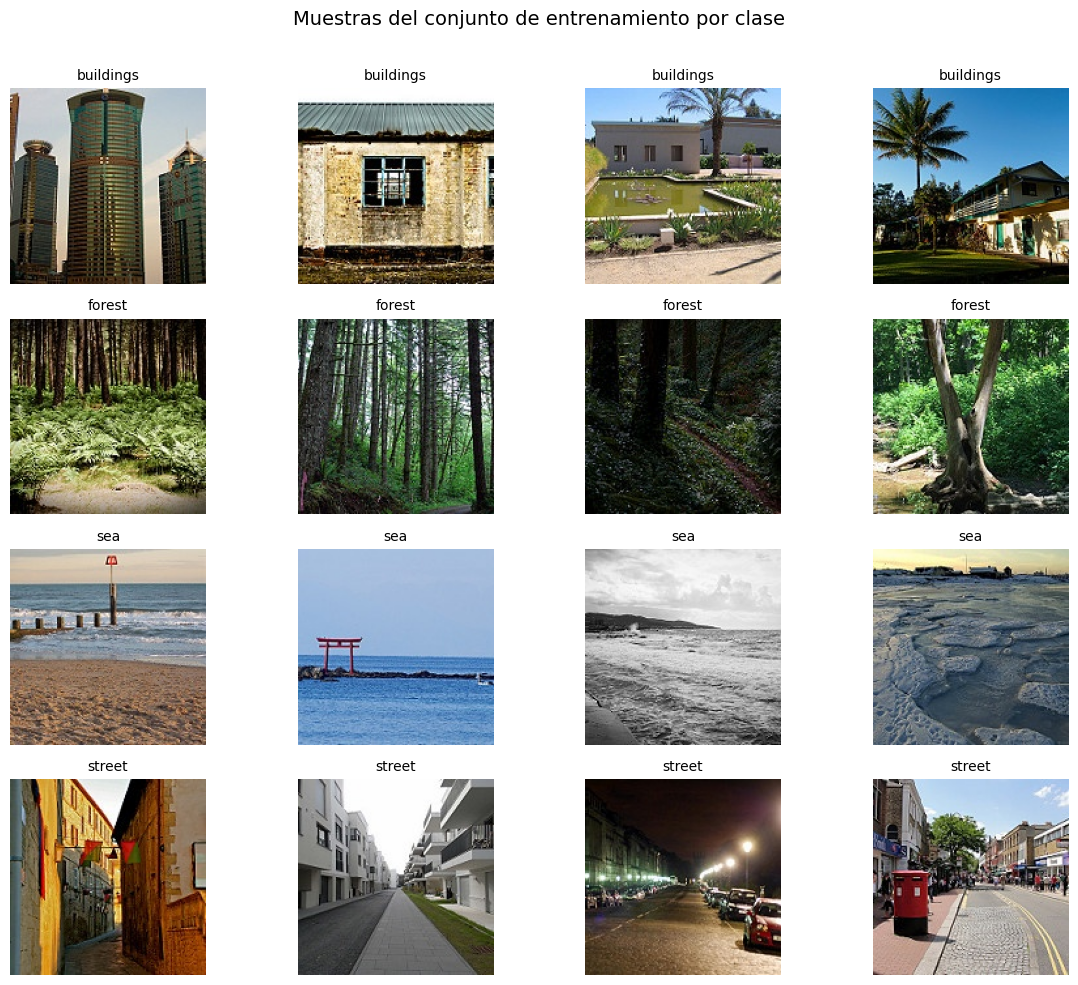

In [ ]:
import random

MUESTRAS_POR_CLASE = 4
rng = random.Random(SEED)

fig, axes = plt.subplots(
    nrows=len(CLASES_SELECCIONADAS),
    ncols=MUESTRAS_POR_CLASE,
    figsize=(12, 10),
    squeeze=False
)

for row, class_name in enumerate(CLASES_SELECCIONADAS):
    class_dir = train_proc / class_name
    image_paths = sorted(
        path for path in class_dir.iterdir()
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    if not image_paths:
        raise FileNotFoundError(f"No se encontraron imágenes para la clase: {class_name}")

    selected_paths = rng.sample(image_paths, k=min(MUESTRAS_POR_CLASE, len(image_paths)))

    for column, axis in enumerate(axes[row]):
        if column < len(selected_paths):
            image_path = selected_paths[column]
            axis.imshow(plt.imread(image_path))
            axis.set_title(class_name, fontsize=10)
        axis.axis("off")

fig.suptitle("Muestras del conjunto de entrenamiento por clase", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

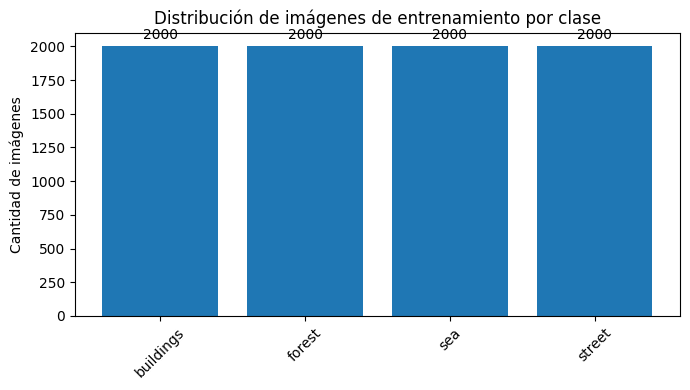

In [ ]:
classes = CLASES_SELECCIONADAS
image_extensions = {".jpg", ".jpeg", ".png"}
counts = [
    sum(
        image_path.is_file() and image_path.suffix.lower() in image_extensions
        for image_path in (train_proc / class_name).iterdir()
    )
    for class_name in classes
]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(classes, counts)
ax.bar_label(bars, padding=3)

plt.xticks(rotation=45)
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de imágenes de entrenamiento por clase")
plt.tight_layout()
plt.show()

El conjunto de datos se encuentra balanceado debido a las limitaciones en la cantidad de imagenes que fueron establecidas, y como las clases poseen la misma cantidad de imagenes. Esto nos permite ver que las diferencias de rendimiento observadas durante la auditoría no se deban, en principio, a un desbalance entre clases.

**2.4 Modelo Convolucional**

En esta estapa del proceso de entrenamiento de nuestro, estaremos viendo principalmente el tamaño de los datos a procesar, la cantidad de canales, cantidad de capas convolucionales, optimizadores y las diferentes metricas utilizadas.

**Capas convolucionales y el porque de ellas:**

En nuestras capas convolucionales comenzaria con nuestra entrada de datos **Input(shape=(TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3))** que toma la misma cantidad de pixeles que se declararon anteriormente en las imagenes ocupando los tres canales de colores RGB (Rojo, Verde y Azul)

Despues pasariamos a reescalar los valores de los pixeles **tf.keras.layers.Rescaling(1.0 / 255)** de las imagenes a un rango estandart de entre 0 y 1, esto ayuda a que el descenso de la gradiente sea mas suave y controlada cosa que ayuda a que llegue a una solucion mas optima y directa para el modelo

Apartir de ellos seguiriamos con nuestras **capas convolucionales** estas son las encargadas de extraer la mayor cantidad de caracteristicas para nuestro modelo de aprendizaje pueda aprovechar los datos y asi mejorar el reconocimiento de las imagenes, todas extraen caracteristicas en porciones de **3x3** de las imagenes, la primera capa consta de **32 filtros** esta es la encargada de extraer las caracteristicas mas simples de la foto como bordes, lineas, esquinas, etc.

Las siquientes capas constans de **64 y 128 filtros** estas serian las encargadas de ya enfocarse en los detalles mas complejos de las imagenes como diferentes tipos de formas, siluetas, patrones especificos del objeto, etc.

El **MaxPooling2D()** lo ocupamos principalmente para extraer lo mejor de cada mapa de caracteristicas individual, y a medida que los filtros iban aumentando nos ayudaba justamente a extraer caracteristicas cada vez mas avanzadas

Nosotros decidimos mantener el uso de la función de **activación ReLU**, esto lo que hace es que no satura el desvanecimiento del gradiente con valores positivos, este nos da una garantia para un aprendizaje continuo en las capas mas profundas de nuestro modelo. Además, este al convertir los valores negativos a cero y mantener los valores positivos ayuda a una buena eficiencia computacional, reduce el tiempo de entrenamiento, genera una representación dispersa (sparsity) que hace al modelo más ligero, robusto y eficiente ante el sobreajuste.

**Optimizador adam**

Como optimizador estaremos utilizando **adam (Adaptive Moment Estimation)** este algoritmo es el encargado de actualizar los pesos a medida que va aprendiendo el modelo para de esta forma minimizar el error


**Loss "categorical_crossentropy"**

Es la función de pérdida que mide qué tan lejos están las predicciones del modelo de las etiquetas reales. Funciona castigando fuertemente al modelo si tiene mucha seguridad en una predicción incorrecta, lo que acelera el aprendizaje al inicio.



**Metricas ["recall", "precision", "f1_score"]**

**Precision (Precisión):** Mide cuántos de los elementos que el modelo clasificó como "Clase X" realmente pertenecían a esa clase. Es vital si el costo de un falso positivo es muy alto.
**Recall (Sensibilidad):** Mide la capacidad del modelo para encontrar todos los casos reales de una clase. Es crítico si no puedes permitirte falsos negativos (ej: omitir una enfermedad o un defecto de fabricación).
**F1-Score:** Es el promedio armónico entre Precision y Recall. Es la métrica definitiva para justificar que el modelo es estable y equilibrado, ideal si tus clases no tienen la misma cantidad de imágenes



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Rescaling

model = Sequential([
    Input(shape=(TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    Conv2D(32, (3, 3), activation="relu", name="conv1"),
    MaxPooling2D(),

    Conv2D(64, (3, 3), activation="relu", name="conv2"),
    MaxPooling2D(),

    Conv2D(128, (3, 3), activation="relu", name="conv3"),
    MaxPooling2D(),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(len(nombre_clases), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy", "recall", "precision", "f1_score"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,716 (2.61 MB)

 Trainable params: 683,716 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

**La cantidad de parámetros que nuestro modelo deberia aprender serian los siguientes:**

El modelo tiene que ajustar y optimizar un total de **683,716 parámetros** entrenables.
Podemos notar cómo la última capa densa (dense_5) tiene exactamente **516 parámetros**, lo cual confirma que el modelo esta adaptado la 4 clases que seleccionamos anteriormente

**Datos guardados en las capas densas**

Los datos de las imágenes de entrada comienzan con 12,288 valores, al pasar por las capas convolucionales (**conv3**) y llegar a la capa de aplanado (**flatten_2**), el modelo extrae y estira las características en un vector de 4,608 datos por imagen, si lo multiplicamos por el batch size de nuestro modelo (32), la primera capa densa (**dense_4**) procesará una matriz de 147,456 datos en cada iteración ($32*4.608$) y apartir de aqui es donde se eleva el esfuerzo computacional debido a la transición de **flatten_2** a **dense_4**, este se lleva 589,952 parámetros, representando casi el 86% de todo el peso del modelo.

## **2.5 Análisis e interpretacion de las métricas**

Al empezar a realizar el modelo decidimos probarlo principalmente con las capas convolucionales y su unica capa densa, estos al no tener ningun tipo de "regulador" o algo que ayudara a la aleatoriedad en el aprendizaje, esto causaba que tuviera una tendencia clara a **overfiting**, al darnos cuenta de esto decidimos dar uso de la funcion **dropout(0.5)** y **early_stopping**

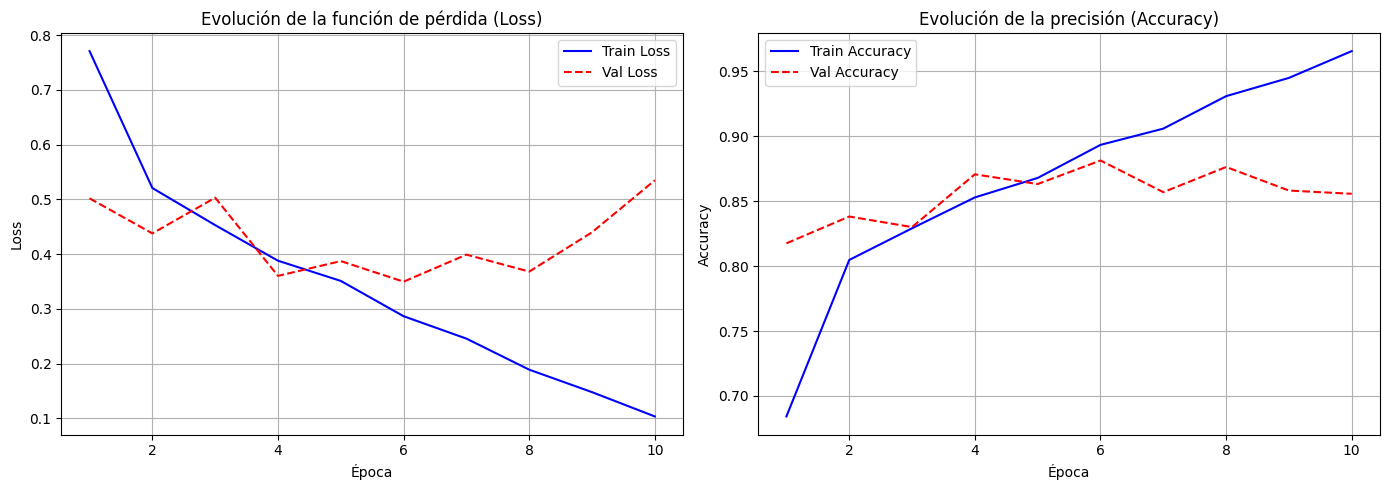

Como nos podemos dar cuenta a travez del grafico del **Loss**, este nos muestra que la validacion de la perdida que desde las primeras epocas tenia una bajada constante (desde la epoca 0 a 4) pero a partir de la 5 epoca a la 10 aproximadamente tenia puntos de subida abruptos, pasando de un loss de aproximadamente $0,39$% a un $0.59$%, basicamente indicando que el modelo estaba empezando a memorizarse los datos

Mientras que en el **Accuracy** desde las epocas 1 a la 6 el **Train Accuracy** sube desde un $68\%$ inicial hasta alcanzar cerca del $89\%$ en la época 6, el Val Accuracy muestra un pico de rendimiento máximo en las épocas 4 y 6 de aproximadamente del ($88$%).   Ya desde las epocas 7 a la 10 el **Train Accuracy** sigue subiendo hasta el 96.5%, la validacion de accuracy se mantiene y cae ligeramente entre el 85% y 86%.   

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.6447 - f1_score: 0.6454 - loss: 0.8544 - precision: 0.7730 - recall: 0.4900 - val_accuracy: 0.7694 - val_f1_score: 0.7653 - val_loss: 0.6129 - val_precision: 0.8484 - val_recall: 0.6575
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7758 - f1_score: 0.7771 - loss: 0.6027 - precision: 0.8212 - recall: 0.7092 - val_accuracy: 0.8344 - val_f1_score: 0.8303 - val_loss: 0.4500 - val_precision: 0.8675 - val_recall: 0.8019
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8058 - f1_score: 0.8069 - loss: 0.5355 - precision: 0.8419 - recall: 0.7548 - val_accuracy: 0.8350 - val_f1_score: 0.8257 - val_loss: 0.4641 - val_precision: 0.8695 - val_recall: 0.8037
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8373 - f1_score: 0.8384 - loss: 0.4498 - precision: 0.8621 - recall: 0.8048 - val_accuracy: 0.8637 - val_f1_score: 0.8622 - val_loss: 0.3752 - val_precision: 0.8791 - val_recal

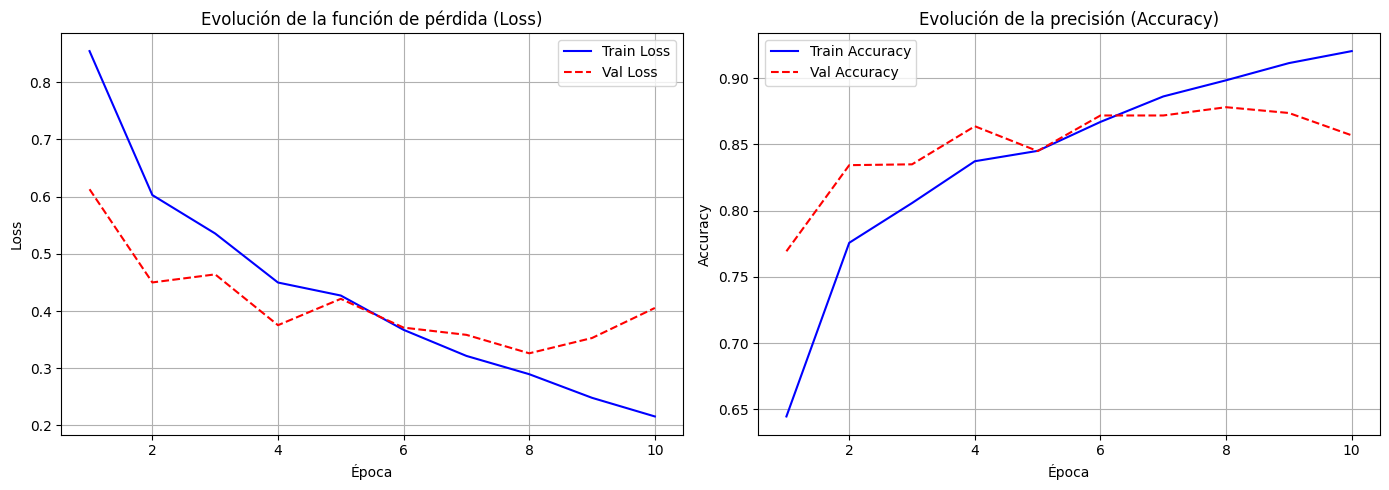

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'models/best_cnn_model.keras',
    monitor='val_loss',
    save_best_only=True
)

epocas = 10
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epocas,
    callbacks=[early_stopping, checkpoint]
)

# Graficar las curvas para las épocas que realmente se ejecutaron
epocas_entrenadas = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epocas_entrenadas, history.history["loss"], label="Train Loss", color="blue")
ax[0].plot(epocas_entrenadas, history.history["val_loss"], label="Val Loss", color="red", linestyle="--")
ax[0].set_title("Evolución de la función de pérdida (Loss)")
ax[0].set_xlabel("Época")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(epocas_entrenadas, history.history["accuracy"], label="Train Accuracy", color="blue")
ax[1].plot(epocas_entrenadas, history.history["val_accuracy"], label="Val Accuracy", color="red", linestyle="--")
ax[1].set_title("Evolución de la precisión (Accuracy)")
ax[1].set_xlabel("Época")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(True)

fig.tight_layout()
plt.show()

**2.6 Resultados del modelo**

Al haber realizado estos cambios pudimos notar una mejora en la estabilidad del aprendizaje, la **Loss** se mantiene en una constante bajada de manera casi limpia, manteniendose en el $40$% **desde la epoca 0 a la 6**, ya de ahi aumental levemente y despues empieza a bajar hasta manterse en un $35$% aproximadamente, sin cambios abruptos, con una bajada paulatina nos da a entender que el modelo aprendio a reconocer las imagenes sin caer en un **sobreajuste**

Los resultados del **Accuracy** de igual forma mantiene una subida paulatina y controlada casi a la par del **Train Accuracy**
subiendo del $75$% hasta un aproximado del $87$%-$88$%

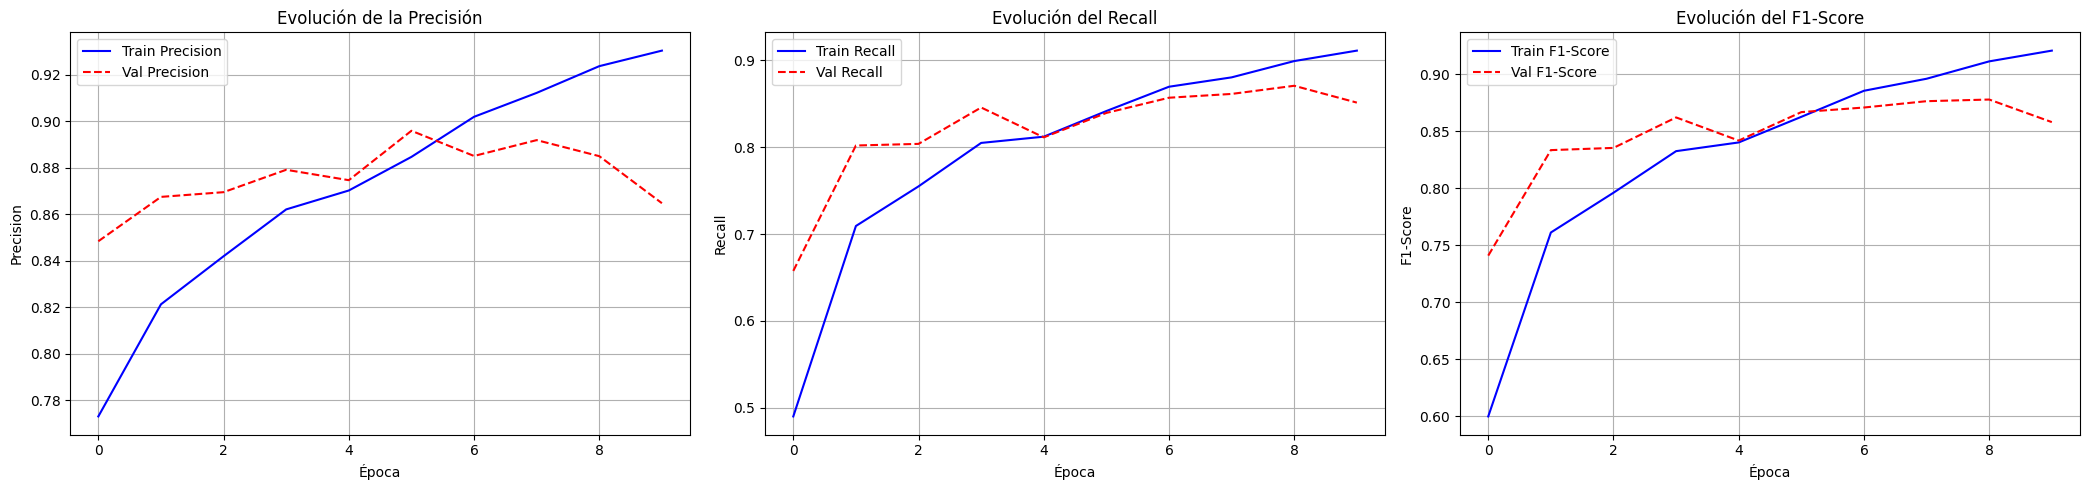

In [ ]:
# Graficar curvas de Precision, Recall y F1-Score
fig, ax = plt.subplots(1, 3, figsize=(21, 5)) # 1 fila, 3 columnas

# Curva de Precision
ax[0].plot(history.history['precision'], label='Train Precision', color='blue')
ax[0].plot(history.history['val_precision'], label='Val Precision', color='red', linestyle='--')
ax[0].set_title('Evolución de la Precisión')
ax[0].set_xlabel('Época')
ax[0].set_ylabel('Precision')
ax[0].legend()
ax[0].grid(True)

# Curva de Recall
ax[1].plot(history.history['recall'], label='Train Recall', color='blue')
ax[1].plot(history.history['val_recall'], label='Val Recall', color='red', linestyle='--')
ax[1].set_title('Evolución del Recall')
ax[1].set_xlabel('Época')
ax[1].set_ylabel('Recall')
ax[1].legend()
ax[1].grid(True)

# Calcular F1-Score a partir de Precision y Recall del historial
train_precision = np.array(history.history['precision'])
train_recall = np.array(history.history['recall'])
train_f1 = 2 * (train_precision * train_recall) / (train_precision + train_recall + 1e-7) # Añadir epsilon para evitar división por cero

val_precision = np.array(history.history['val_precision'])
val_recall = np.array(history.history['val_recall'])
val_f1 = 2 * (val_precision * val_recall) / (val_precision + val_recall + 1e-7)

# Curva de F1-Score
ax[2].plot(train_f1, label='Train F1-Score', color='blue')
ax[2].plot(val_f1, label='Val F1-Score', color='red', linestyle='--')
ax[2].set_title('Evolución del F1-Score')
ax[2].set_xlabel('Época')
ax[2].set_ylabel('F1-Score')
ax[2].legend()
ax[2].grid(True)

plt.tight_layout() # Ajustar el diseño para evitar superposiciones
plt.show()

Y de igual manera viendo detalladamente las métricas de la **precision, recall y f1-score** se puede confirmar una buena capacidad de clasificación de nuestro modelo. La curva de Recall de validación logra superar de una forma bastante consistente la metrica que antes habiamos propuesto del $85\%$, alcanzando un valor final de $87\%$ aproximadamente. Por otra parte, la Precisión y el F1-Score de validación se mantienen rondando en torno al $90\%$ y $88\%$, esto basicamente nos dice que la poca diferencia entre los conjuntos de entrenamiento y validación en las tres métricas valida nustra decision de la aplicacion del **Dropout(0.5)** con el **early_stopping** para poder prevenir la memorización y garantizar un aprendizaje generalizable.

## **2.7 Matriz de confusion y su interpretacion**

Para poder identificar de manera mas certera la cantidad de clases confundidas y las clases correctamente predichas se realizo la siguiente matriz de confusion


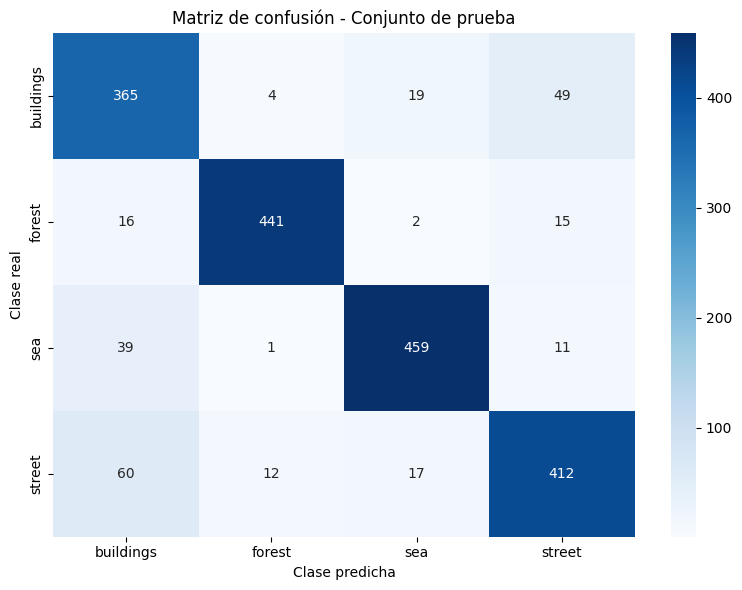

INFORME DE CLASIFICACIÓN
              precision    recall  f1-score   support

   buildings     0.7604    0.8352    0.7961       437
      forest     0.9629    0.9304    0.9464       474
         sea     0.9235    0.9000    0.9116       510
      street     0.8460    0.8224    0.8340       501

    accuracy                         0.8725      1922
   macro avg     0.8732    0.8720    0.8720      1922
weighted avg     0.8759    0.8725    0.8737      1922



In [ ]:

# MATRIZ DE CONFUSION SOBRE EL CONJUNTO PRUEBA

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

y_real = []
y_predicho = []

for imagenes, etiquetas, in test_dataset:
  probabilidades = model.predict(imagenes, verbose=0)

  y_real.extend(np.argmax(etiquetas.numpy(), axis=1))
  y_predicho.extend(np.argmax(probabilidades, axis=1))

y_real = np.array(y_real)
y_predicho = np.array(y_predicho)

# Calcular la matriz
matriz = confusion_matrix(
    y_real,
    y_predicho,
    labels=np.arange(len(nombre_clases))
)

# Graficar
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombre_clases,
    yticklabels=nombre_clases
)

plt.title("Matriz de confusión - Conjunto de prueba")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

# Informe por clase
print("INFORME DE CLASIFICACIÓN")
print(
    classification_report(
        y_real,
        y_predicho,
        labels=np.arange(len(nombre_clases)),
        target_names=nombre_clases,
        zero_division=0,
        digits=4
    )
)

Como se predijo anteriormente las clases que tuvieron un mayor indice de confusion fueron **buildings** con **street** con una cantidad total de predicciones confundidas de **63**, confirmando la primera hipotesis de las clases que el modelo tenia mayor probabilidad de confundir, en este caso debido justamente a los colores y diferentes construcciones que se podian llegar a apreciar en ambas imagene, en cambio, la confusion predicha entre **buildings** y **forest** fue mucho menor de lo esperado

### **2.8 Auditoría de Aciertos y Errores**

Aca podemos hacer un refuerzo de lo que nuestra teoria anterior (antes de realizar el entrenamiento del modelo) estaba concretando, podemos ver un ejemplo de como el modelo se equivoco al momento de querer predecir un **building** de una **street**,
estas predicciones erroneas como anteriormente fue mencionado, se pudo deber principalmente a los colores como tambien ciertas formas de edificios o estructuras que en la clase de **street** podria contener parecidos con **buildings** y debido a esto hacer que el modelo prediga o clasifique erroneamente, de igual forma a pesar de que fueron las clases con mayor error en sus predicciones, tambien se incluyeron mas ejemplos para las clases **forest y sea** y asi observar de una manera mas grafica los errores que tuvo el modelo al predecir.    

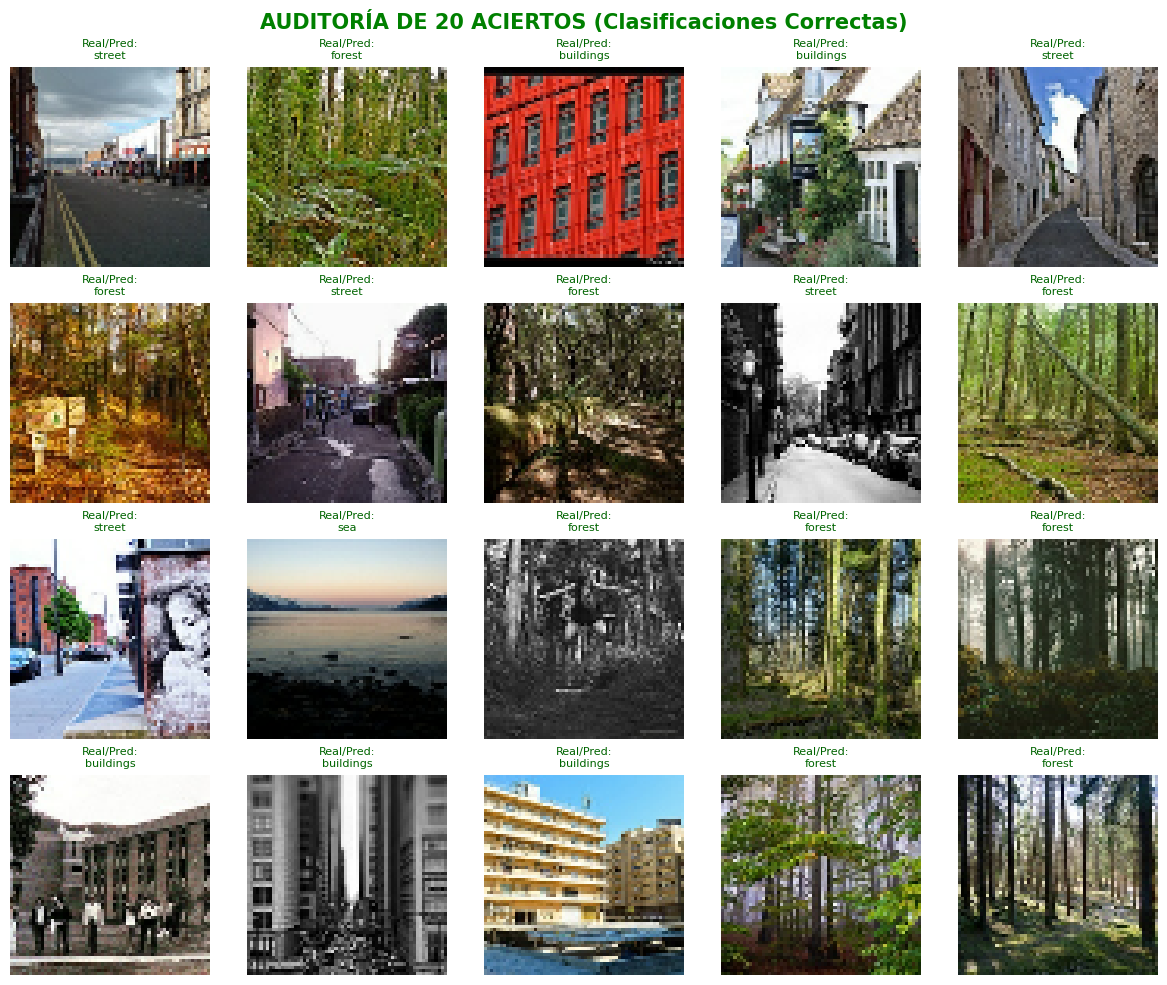

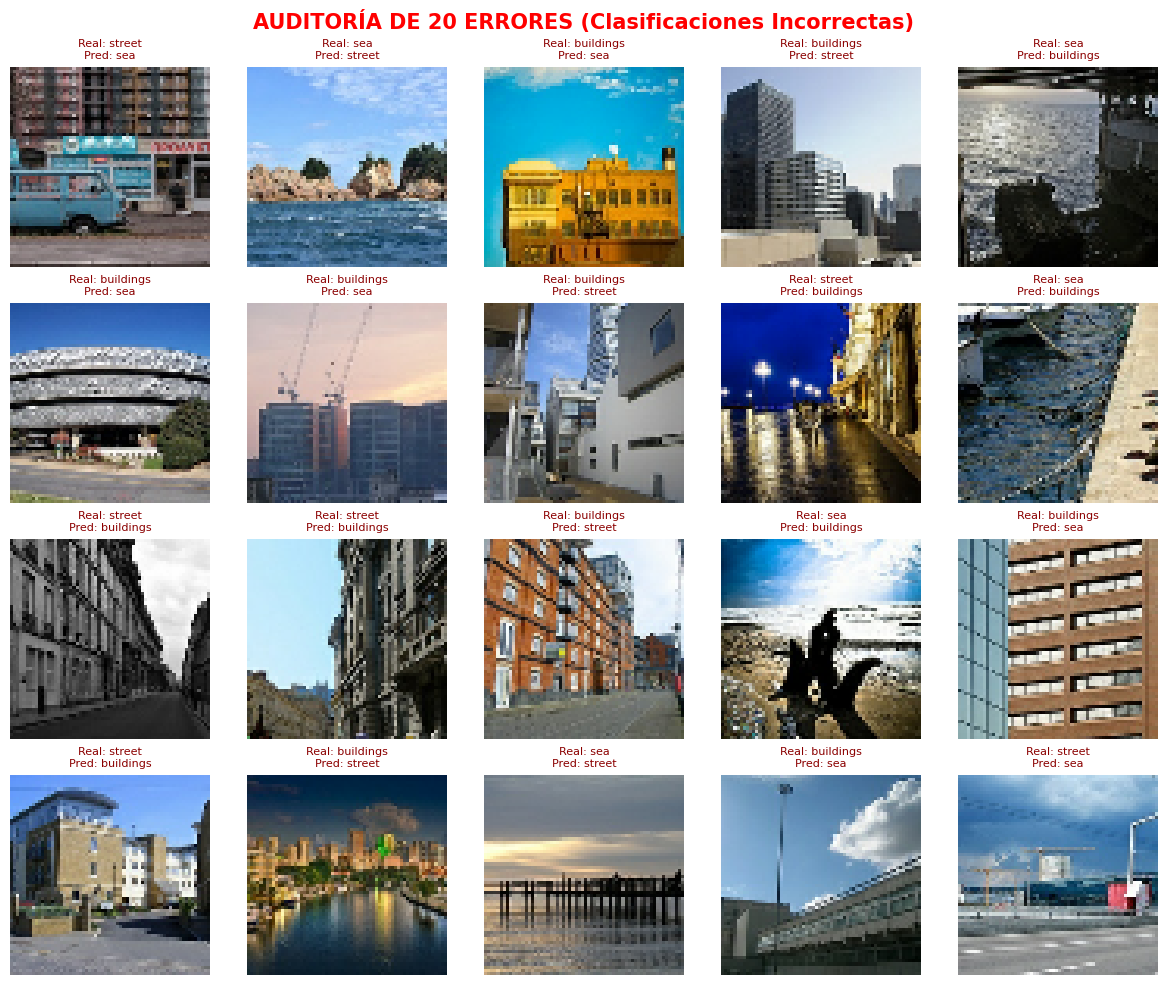

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Recopilar todas las predicciones, imágenes y etiquetas reales del conjunto de pruebas completo
todas_las_imagenes = []
todas_las_etiquetas = []
todas_las_predicciones = []

for imagenes_lote, etiquetas_lote in test_dataset:
    preds_lote = model.predict(imagenes_lote, verbose=0)

    todas_las_imagenes.extend(imagenes_lote.numpy())
    todas_las_etiquetas.extend(np.argmax(etiquetas_lote.numpy(), axis=1))
    todas_las_predicciones.extend(np.argmax(preds_lote, axis=1))

todas_las_imagenes = np.array(todas_las_imagenes)
todas_las_etiquetas = np.array(todas_las_etiquetas)
todas_las_predicciones = np.array(todas_las_predicciones)

# 2. Separar los índices de aciertos y de fallas
indices_aciertos = np.where(todas_las_predicciones == todas_las_etiquetas)[0]
indices_errores = np.where(todas_las_predicciones != todas_las_etiquetas)[0]

# Tomar un máximo de 20 muestras representativas para cada caso
cantidad_muestras = 20

# Usar una selección aleatoria para ver variedad en las imágenes auditadas
np.random.seed(SEED)
aciertos_seleccionados = np.random.choice(
    indices_aciertos,
    size=min(cantidad_muestras, len(indices_aciertos)),
    replace=False
)
errores_seleccionados = np.random.choice(
    indices_errores,
    size=min(cantidad_muestras, len(indices_errores)),
    replace=False
)

# 3. Graficar los 20 Aciertos en un formato compacto (4 filas x 5 columnas)
fig_aciertos, axes_aciertos = plt.subplots(4, 5, figsize=(12, 10))
fig_aciertos.suptitle("AUDITORÍA DE 20 ACIERTOS (Clasificaciones Correctas)", fontsize=15, color="green", weight="bold")

for i, idx in enumerate(aciertos_seleccionados):
    ax = axes_aciertos[i // 5, i % 5]
    # Convertir a rango 0-255 e int para mostrar de forma nativa si es necesario
    img_mostrar = todas_las_imagenes[idx].astype("uint8")
    ax.imshow(img_mostrar)

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    ax.set_title(f"Real/Pred:\n{clase_real}", fontsize=8, color="darkgreen")
    ax.axis('off')

# Rellenar ejes vacíos si hubiese menos de 20 aciertos
for j in range(len(aciertos_seleccionados), 20):
    axes_aciertos[j // 5, j % 5].axis('off')

plt.tight_layout()
plt.show()

# 4. Graficar los 20 Errores en un formato compacto (4 filas x 5 columnas)
fig_errores, axes_errores = plt.subplots(4, 5, figsize=(12, 10))
fig_errores.suptitle("AUDITORÍA DE 20 ERRORES (Clasificaciones Incorrectas)", fontsize=15, color="red", weight="bold")

for i, idx in enumerate(errores_seleccionados):
    ax = axes_errores[i // 5, i % 5]
    img_mostrar = todas_las_imagenes[idx].astype("uint8")
    ax.imshow(img_mostrar)

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]
    ax.set_title(f"Real: {clase_real}\nPred: {clase_pred}", fontsize=8, color="darkred")
    ax.axis('off')

# Rellenar ejes vacíos si hubiese menos de 20 errores
for j in range(len(errores_seleccionados), 20):
    axes_errores[j // 5, j % 5].axis('off')

plt.tight_layout()
plt.show()

## **2.9 Visualizacion de los feature maps**

En esta seccion estaremos analizando las posibles razones del porque nuestro modelo se pudo estar equivocando en las predicciones de nuestras 4 clases seleccionadas, viendo las diferentes feature maps de cada una, tomando en cuenta los lugares de mayor activacion y las zonas que se podria considerar que estan siendo ignoradas.

-  **Predicciones erroneas para street:** Tomamos 3 ejemplos de predicciones de que se suponian que debian ser **street** pero terminaron siendo reconocidas como **buildings**, la razon principal de estos que se repiten en los 3 casos respectivos que decidimos analizar, son las lineas rectas perfectas y paletas de colores parecidas, **¿Porque?**, en el **caso 1**, aparte de que la foto apunta directamente a estructuras que facilmente al ojo podria ser considerado un **building**, como se puede notar en el feature map se fija casi unicamente en las lineas que conforman los edificios apuntados en la foto causando que aunque la foto realmente sea un **street** el modelo lo termine considerando **building**. En el **caso 2** sucede algo parecido se sigue fijando en lineas, cosa que haga que termine ignorando completamente el camino que se muestra en la foto a abajo de los edificios, y por ultimo, en el **caso 3** practicamente se repite lo que llevamos comentando.



Se encontraron 89 predicciones erróneas para 'street'.
Visualizando Feature Maps para los índices de prueba: [1421, 1434, 1438]



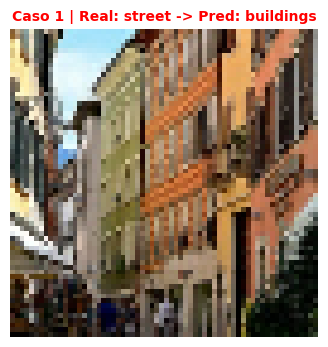

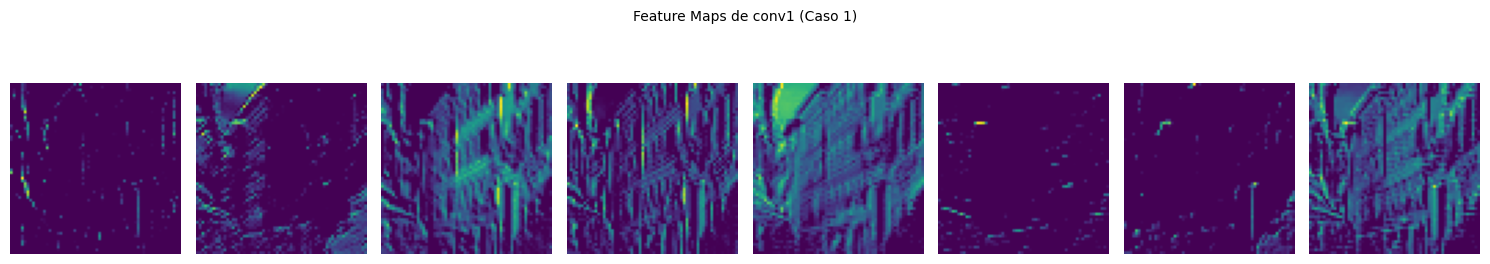

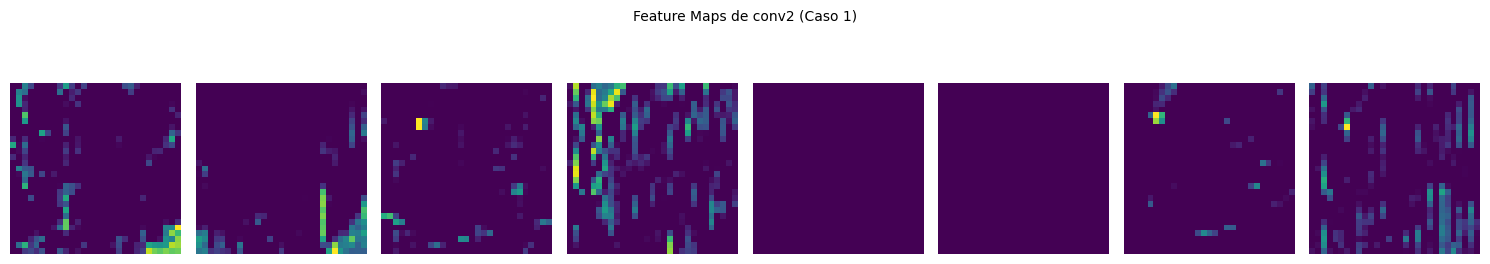

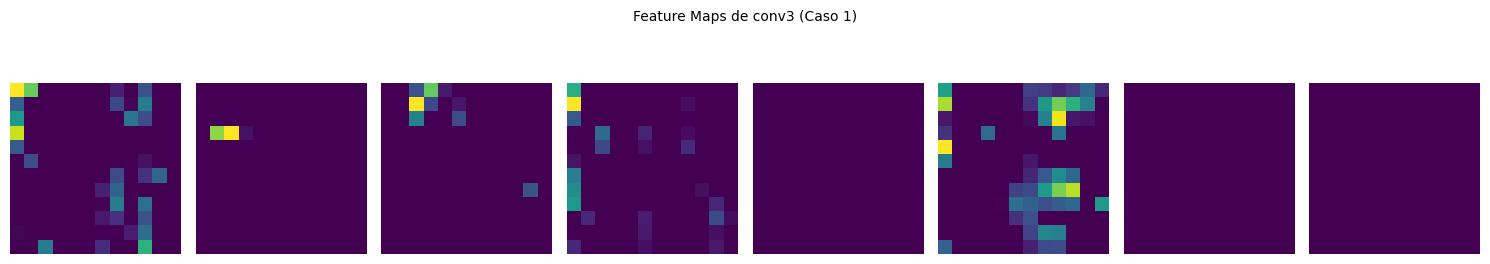

--------------------------------------------------------------------------------


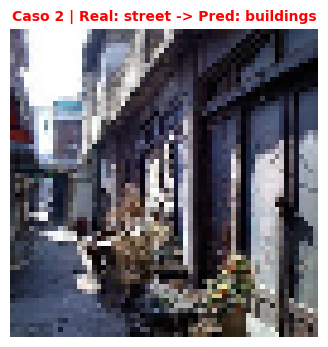

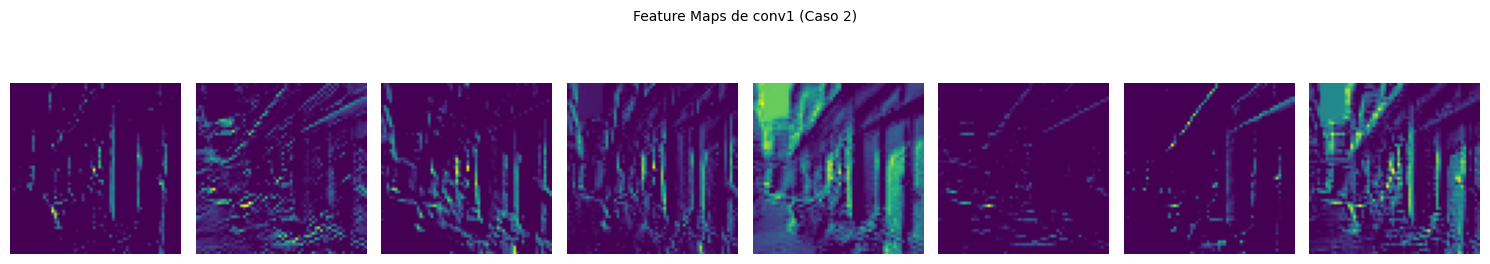

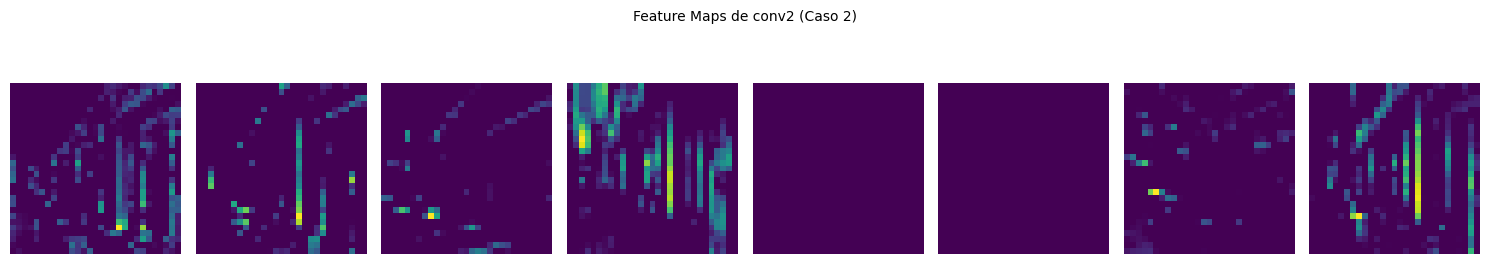

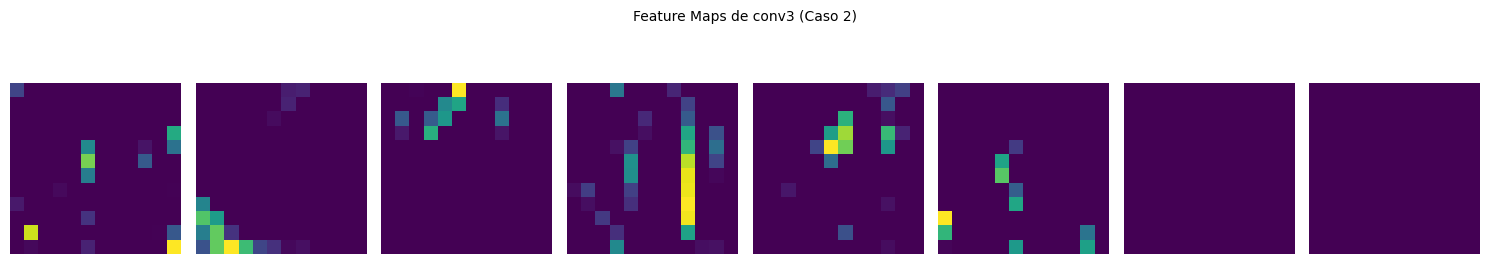

--------------------------------------------------------------------------------


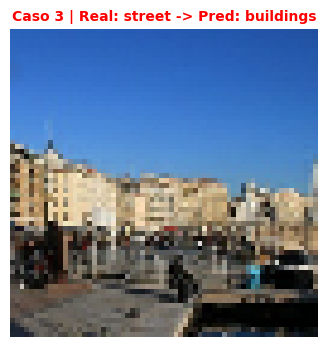

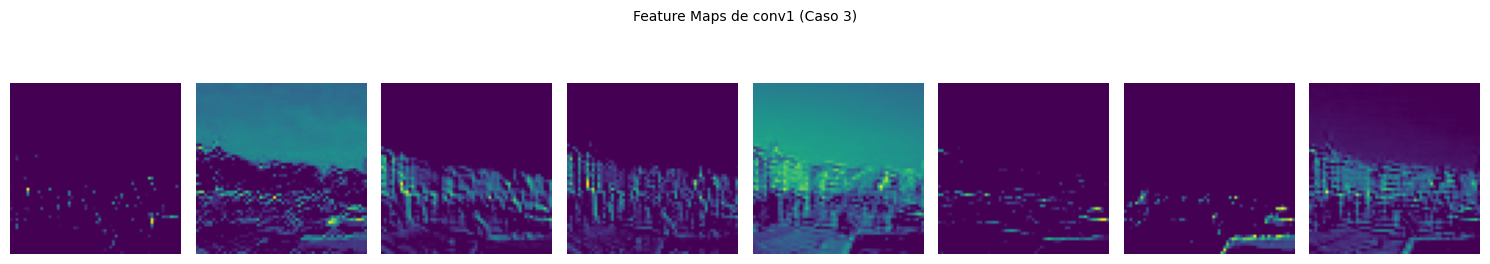

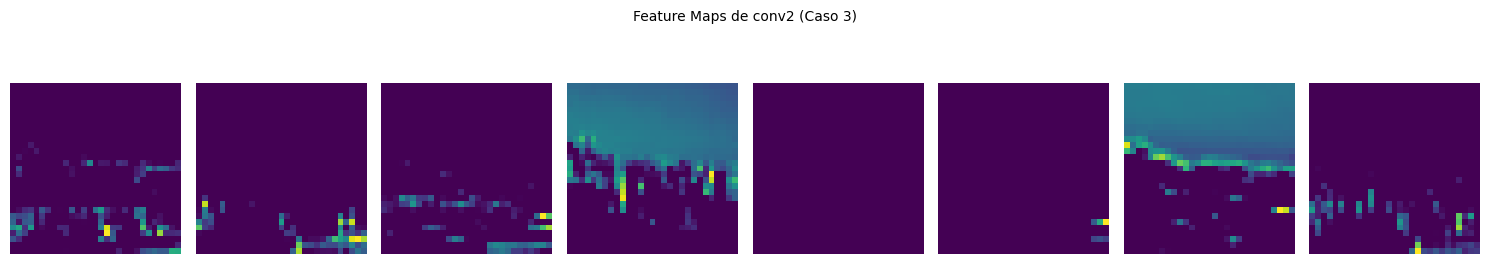

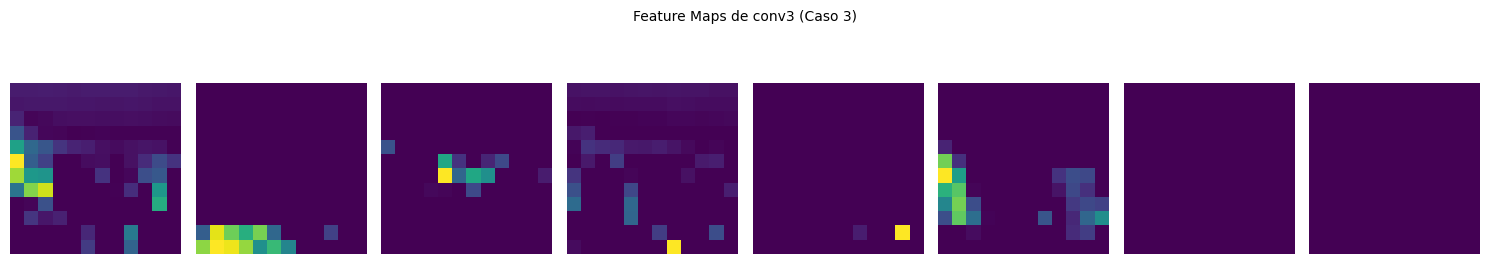

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf

# 1. Identificar el índice correspondiente a la clase 'street'
idx_street = nombre_clases.index('street')

# 2. Filtrar las muestras reales de 'street' que fueron clasificadas erróneamente
indices_street_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_street and pred != idx_street:
        indices_street_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de street
muestras_seleccionadas = indices_street_erroneos[:3]
print(f"Se encontraron {len(indices_street_erroneos)} predicciones erróneas para 'street'.")
print(f"Visualizando Feature Maps para los índices de prueba: {muestras_seleccionadas}\n")

# 3. Crear el modelo auxiliar de activaciones
modelo_activaciones = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("conv1").output,
        model.get_layer("conv2").output,
        model.get_layer("conv3").output
    ]
)

# 4. Iterar sobre las 3 imágenes seleccionadas para graficar sus activaciones
for num, idx in enumerate(muestras_seleccionadas):
    # Preparar la imagen para el modelo (añadiendo dimensión de batch)
    img_raw = todas_las_imagenes[idx]
    img_tensor = tf.expand_dims(img_raw, axis=0)

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Mostrar la imagen original con su diagnóstico
    plt.figure(figsize=(4, 4))
    plt.imshow(img_raw.astype("uint8"))
    plt.title(f"Caso {num+1} | Real: {clase_real} -> Pred: {clase_pred}", color='red', fontsize=10, fontweight='bold')
    plt.axis("off")
    plt.show()

    # Obtener las activaciones de las capas convolucionales
    activaciones = modelo_activaciones.predict(img_tensor, verbose=0)

    # Mostrar mapas de características para conv1, conv2 y conv3
    for nombre_capa, activacion in zip(["conv1", "conv2", "conv3"], activaciones):
        mapas = activacion[0]
        cantidad = min(8, mapas.shape[-1])  # Mostrar hasta 8 filtros

        fig, axes = plt.subplots(1, cantidad, figsize=(15, 2.5))
        fig.suptitle(f"Feature Maps de {nombre_capa} (Caso {num+1})", fontsize=10, y=1.08)

        for i in range(cantidad):
            ax = axes[i] if cantidad > 1 else axes
            if nombre_capa == "conv1":
                # conv1 tiene canales de color directos
                ax.imshow(mapas[:, :, i], cmap="viridis")
            else:
                # Capas posteriores se promedian los canales o se grafican directamente
                ax.imshow(mapas[:, :, i], cmap="viridis")
            ax.axis("off")

        plt.tight_layout()
        plt.show()
    print("-" * 80)

-  **Predicciones erroneas para buildings:** Tomamos 3 ejemplos de predicciones de que se suponian que debian ser **buildings** pero terminaron siendo reconocidas como **street**.

En el **caso 1** tubo una fijansion en bordes horizontales y las texturas del suelo en varios mapas de características (especialmente el 5, 6 y 8 de izquierda a derecha) activan con mucha mas intensidad la zona inferior y central de la foto, capturando las texturas horizontales del suelo y el espacio abierto a nivel de calle, como tambien generando una pérdida de la estructura vertical de los edificios los primeros filtros de la red le dieron más peso a las líneas de perspectiva, la calle y los elementos urbanos a pie de calle en lugar de resaltar las fachadas o las siluetas de los edificios.

En el **caso 2** la nieve fue la principal causal de este error en casi todos los feature maps (especialmente el 5 y el 8), la parte inferior con nieve genera una región muy amplia de iluminación y activación, lo que la termina asociando fuertemente a vías, calles, etc, tambien las ramas y texturas dificiles de reconocer en lugar de las formas claras, las ramas de los árboles cubiertas de nieve a la derecha agregan ruido visual (bordes diagonales y dispersos en la 2, 6 y 7 del mapa) esto hacia menos reconocibles las líneas verticales limpias de la construccion.

En el **caso 3** tiene una fuerte activación de líneas en varios filtros (especialmente el 2, 6 y 7), se ven con mucha mas claridad las líneas diagonales de la acera y del la casa, estas líneas dirigen la atención visual hacia la profundidad del camino o el callejón a la izquierda de la foto y el   predominio del espacio abierto, en los mapas con iluminación global (como el 5 y 8), la red visualiza de manera mas activa tanto la acera/calle en primer plano como tambien la vía despejada que se extiende hacia el fondo de la foto.

Se encontraron 72 predicciones erróneas para 'buildings'.
Visualizando Feature Maps para los índices de prueba: [7, 20, 22]



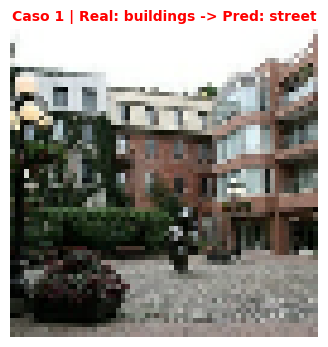

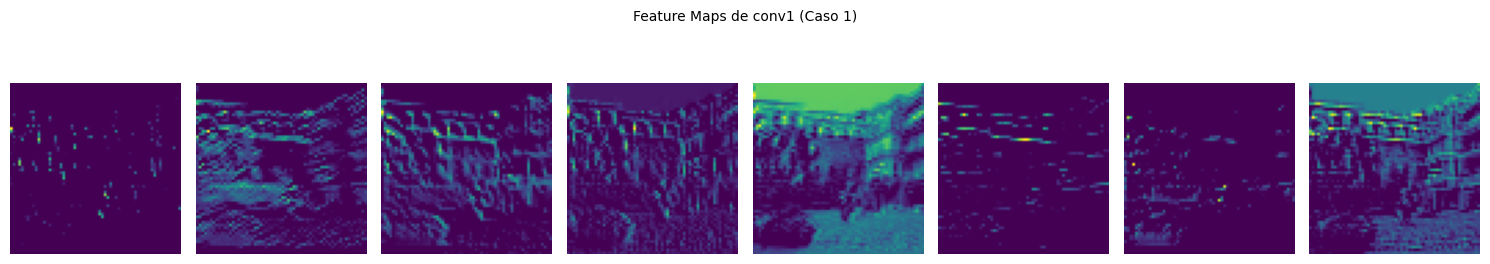

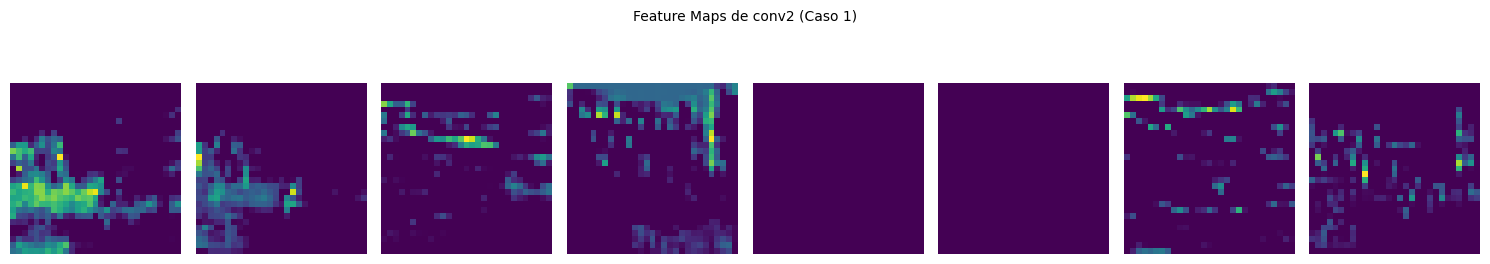

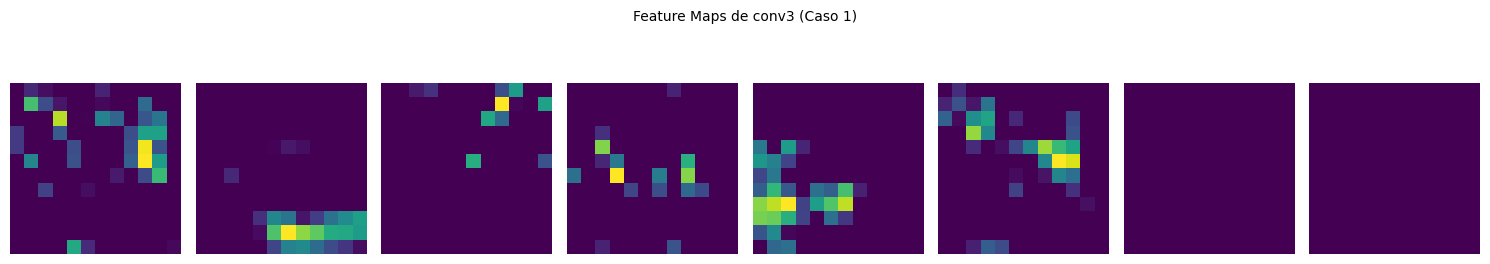

--------------------------------------------------------------------------------


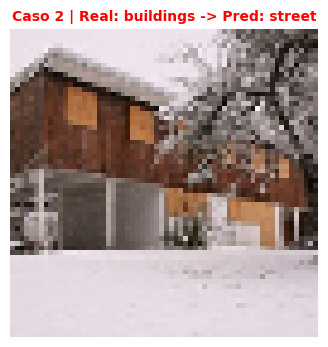

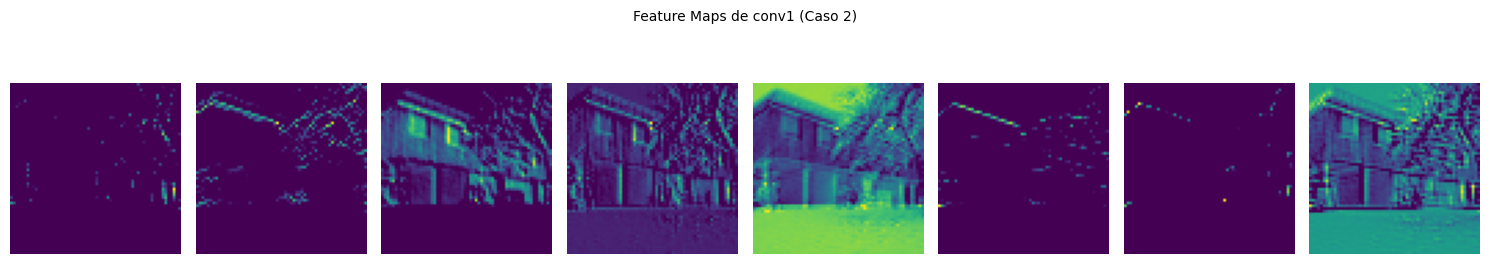

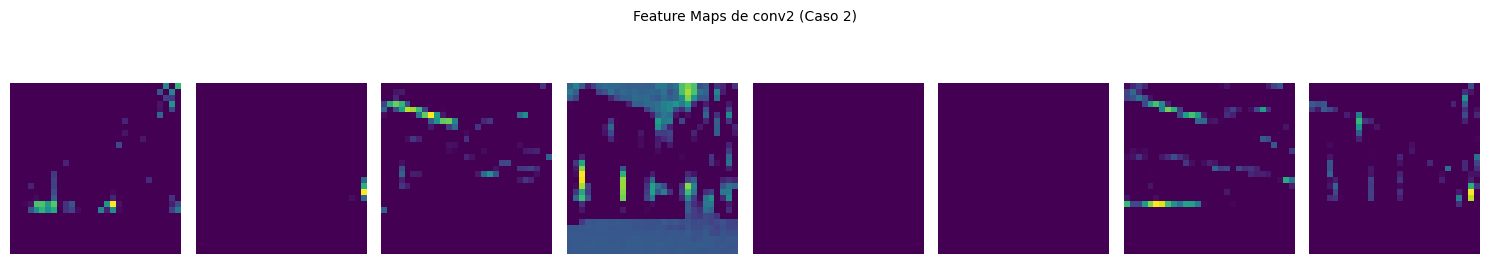

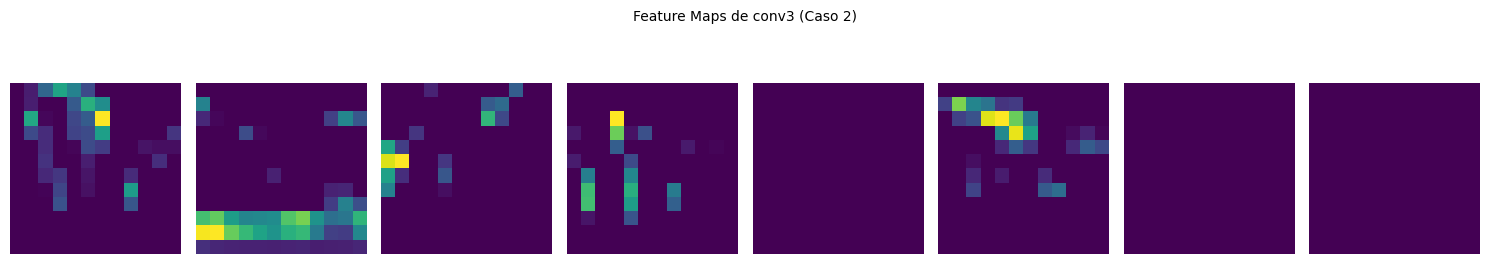

--------------------------------------------------------------------------------


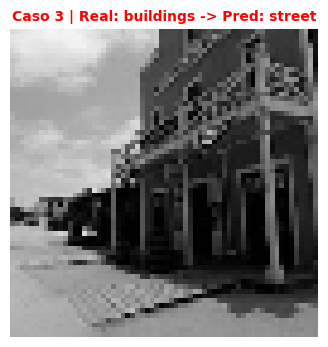

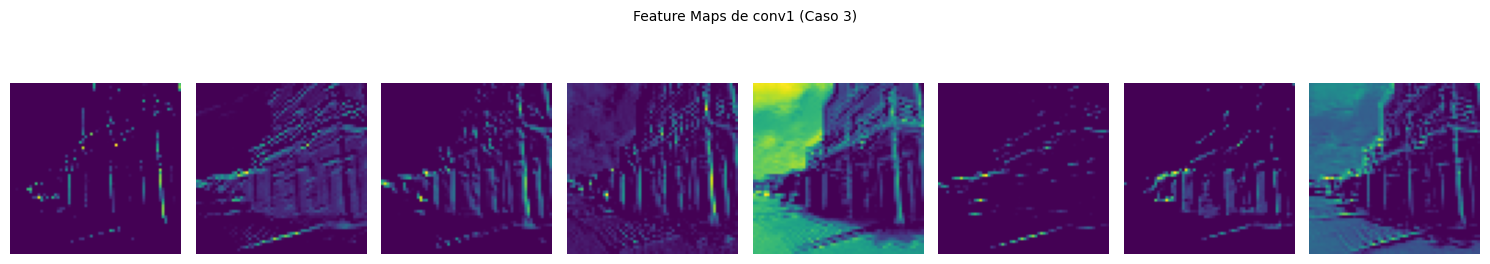

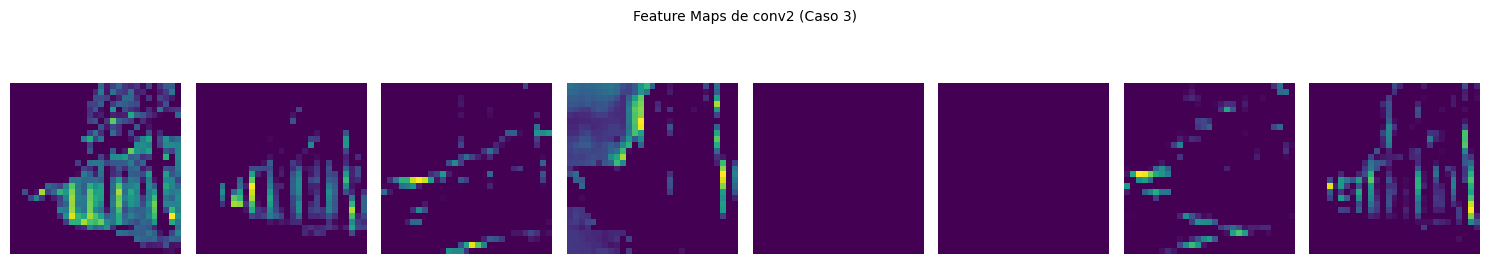

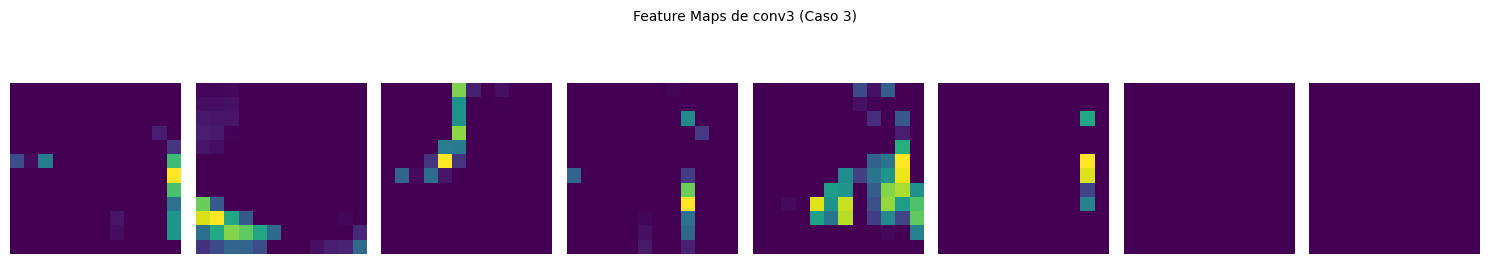

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Identificar el índice correspondiente a la clase 'buildings'
idx_buildings = nombre_clases.index('buildings')

# 2. Filtrar las muestras reales de 'buildings' que fueron clasificadas erróneamente
indices_buildings_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_buildings and pred != idx_buildings:
        indices_buildings_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de buildings
muestras_buildings_sel = indices_buildings_erroneos[:3]
print(f"Se encontraron {len(indices_buildings_erroneos)} predicciones erróneas para 'buildings'.")
print(f"Visualizando Feature Maps para los índices de prueba: {muestras_buildings_sel}\n")

# 3. Crear el modelo auxiliar de activaciones (si no está ya creado)
modelo_activaciones = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("conv1").output,
        model.get_layer("conv2").output,
        model.get_layer("conv3").output
    ]
)

# 4. Iterar sobre las 3 imágenes seleccionadas para graficar sus activaciones
for num, idx in enumerate(muestras_buildings_sel):
    # Preparar la imagen para el modelo
    img_raw = todas_las_imagenes[idx]
    img_tensor = tf.expand_dims(img_raw, axis=0)

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Mostrar la imagen original con su diagnóstico
    plt.figure(figsize=(4, 4))
    plt.imshow(img_raw.astype("uint8"))
    plt.title(f"Caso {num+1} | Real: {clase_real} -> Pred: {clase_pred}", color='red', fontsize=10, fontweight='bold')
    plt.axis("off")
    plt.show()

    # Obtener las activaciones de las capas convolucionales
    activaciones = modelo_activaciones.predict(img_tensor, verbose=0)

    # Mostrar mapas de características para conv1, conv2 y conv3
    for nombre_capa, activacion in zip(["conv1", "conv2", "conv3"], activaciones):
        mapas = activacion[0]
        cantidad = min(8, mapas.shape[-1])  # Mostrar hasta 8 filtros

        fig, axes = plt.subplots(1, cantidad, figsize=(15, 2.5))
        fig.suptitle(f"Feature Maps de {nombre_capa} (Caso {num+1})", fontsize=10, y=1.08)

        for i in range(cantidad):
            ax = axes[i] if cantidad > 1 else axes
            ax.imshow(mapas[:, :, i], cmap="viridis")
            ax.axis("off")

        plt.tight_layout()
        plt.show()
    print("-" * 80)

-  **Predicciones erroneas para sea:** Tomamos 3 ejemplos de predicciones de que se suponian que debian ser **sea** pero terminaron siendo reconocidas como **buildings**

En el **caso 1** la activación de bordes rugosos y rocas verticales, en la mayoría de los mapas de características (especialmente el 3, 4, 5 y 8), la mitad de la derecha de la imagen genera activaciones muy fuertes y estructuradas, los filtros detectaron los bordes irregulares, tonos claros y grietas de las rocas/acantilado como si fueran la textura rugosa de una fachada de piedra, ladrillos o ventanas de un edificio la ausencia de un horizonte acuático claro no presenta las líneas horizontales continuas típicas del mar ni el tono azul homogéneo habitual, quedando muy oscura en casi todos los mapas (1.º, 6.º y 7.º).

En el **caso 2** el dominio del muelle tiene una mayor influencia en el error de la prediccion, en la mayoría de los mapas de características (especialmente el 3, 4, 5 y 8), el muelle activa bordes continuos muy marcados y fuertes, la red asocio estas estructuras verticales y perfectas con muros, columnas o fachadas de construccciones, las texturas complejas en el agua del puerto no se presentan ni plana ni uniforme, tiene cabos, redes, barcos y reflejos que crean un patrón de red o cuadrícula (muy visible en el 2 y 8 mapa) estas texturas rugosas fueron malinterpretadas como detalles arquitectónicos (ventanas, ladrillos o marcos)

En el **caso 3** el predominio de la estructura sólida en primer plano, en la mayoría de los mapas de características (especialmente el 3, 4, 5 y 8), la estructura roja del barco o bote ocupa casi toda la mitad inferior de la imagen activando bordes curvos, pliegues y bordes muy marcados, la pérdida de la textura del agua y horizonte aparente, salvo en el 2.º mapa (que activa la franja del horizonte/cielo), el agua queda completamente tapada por la superficie rígida del primer plano, al mismo tiempo, las líneas paralelas horizontales de la cubierta y los bordes rectos/curvos del bote (6 y 8 en el mapa) engañan a los filtros, asemejándose a techos, tejados o paredes

Se encontraron 51 predicciones erróneas para 'sea'.
Visualizando Feature Maps para los índices de prueba: [912, 923, 937]



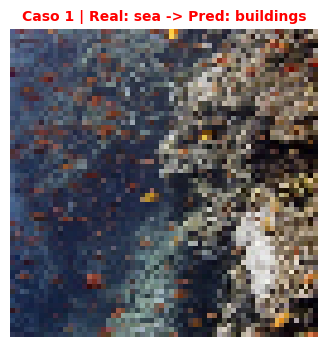

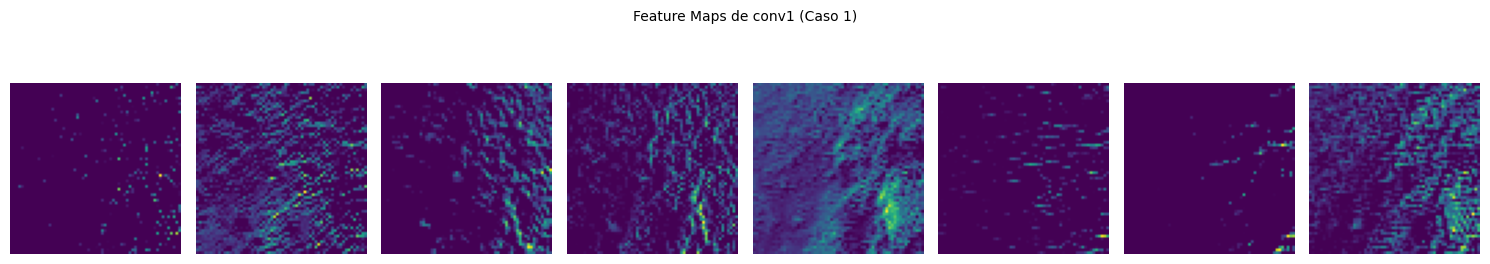

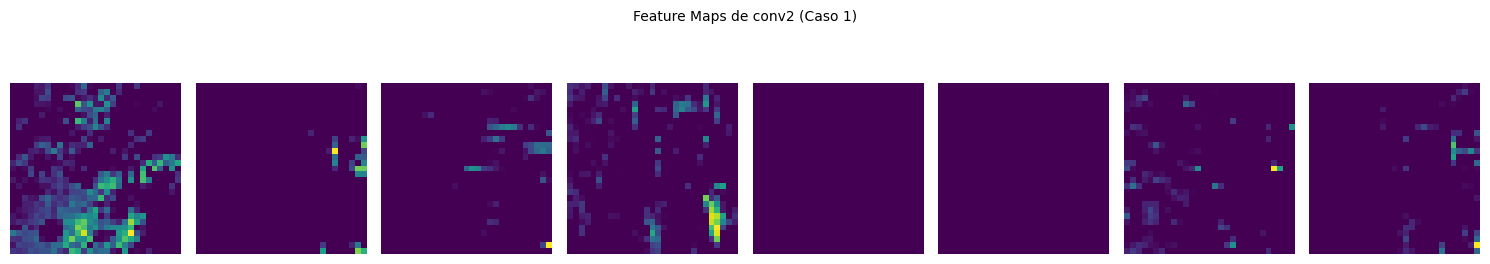

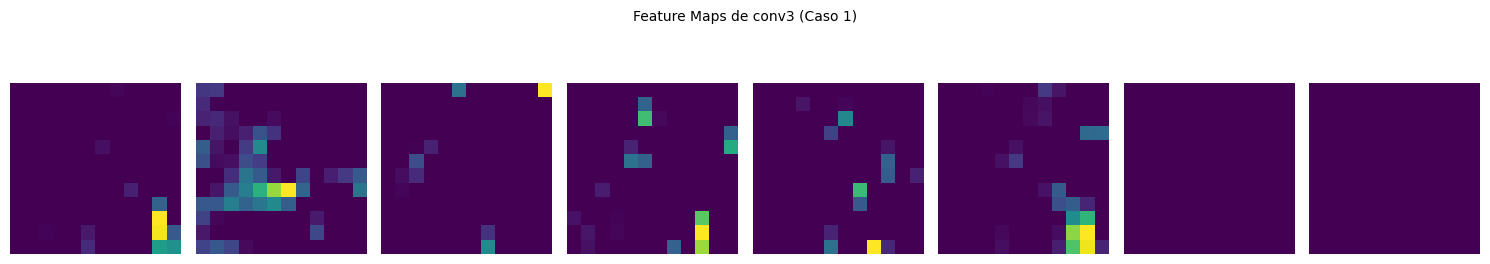

--------------------------------------------------------------------------------


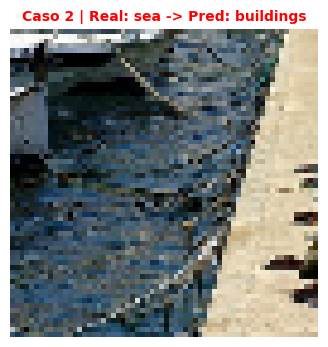

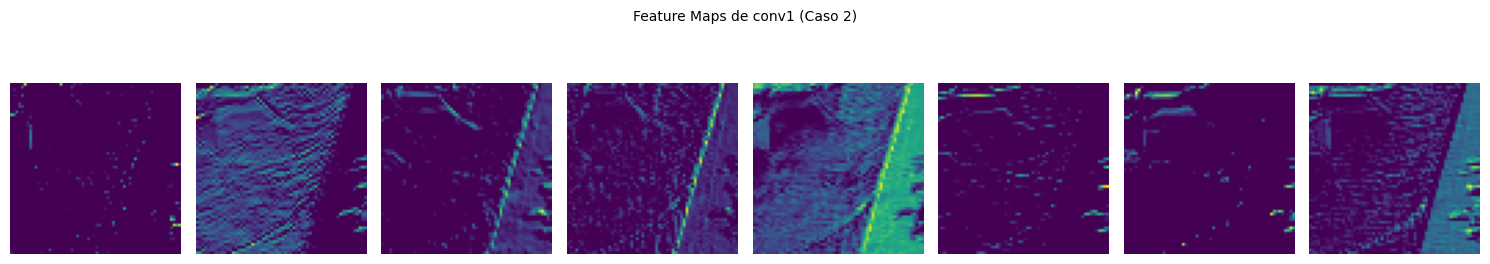

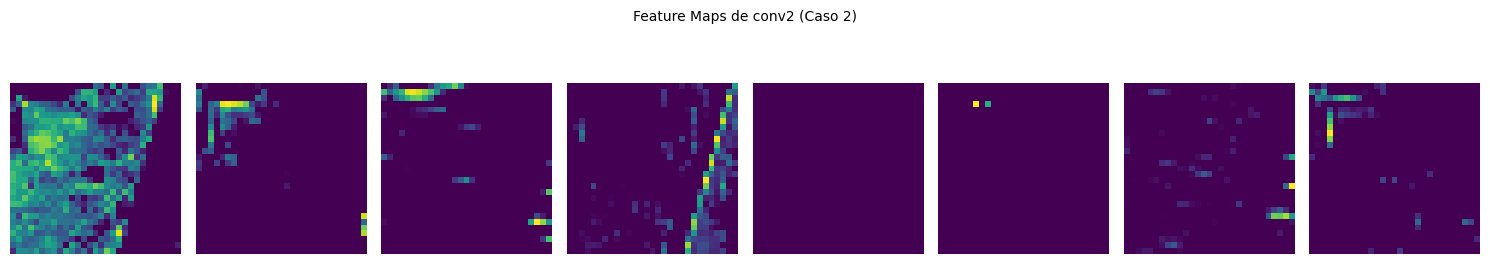

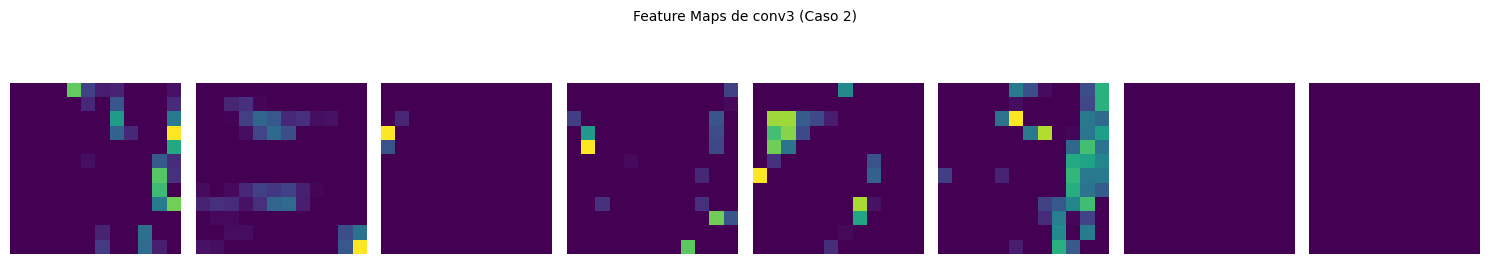

--------------------------------------------------------------------------------


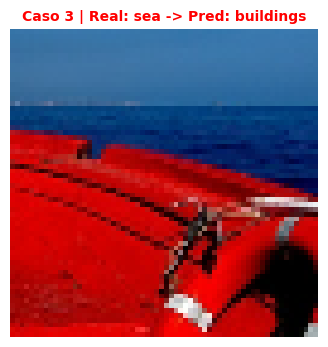

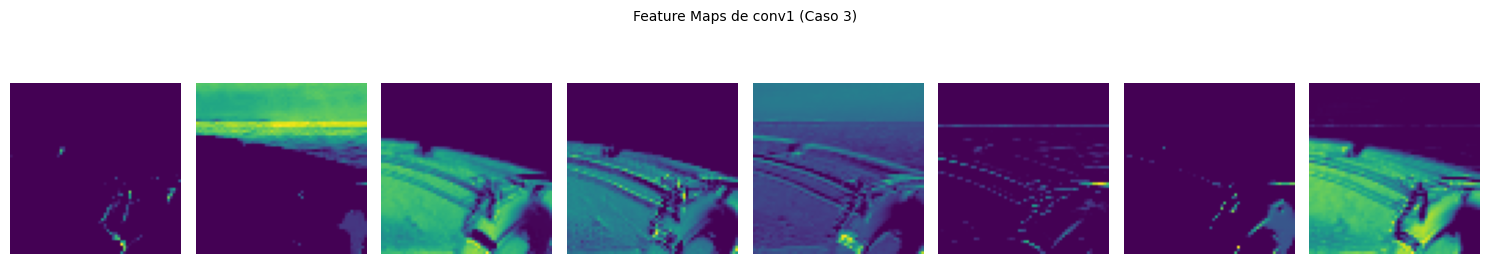

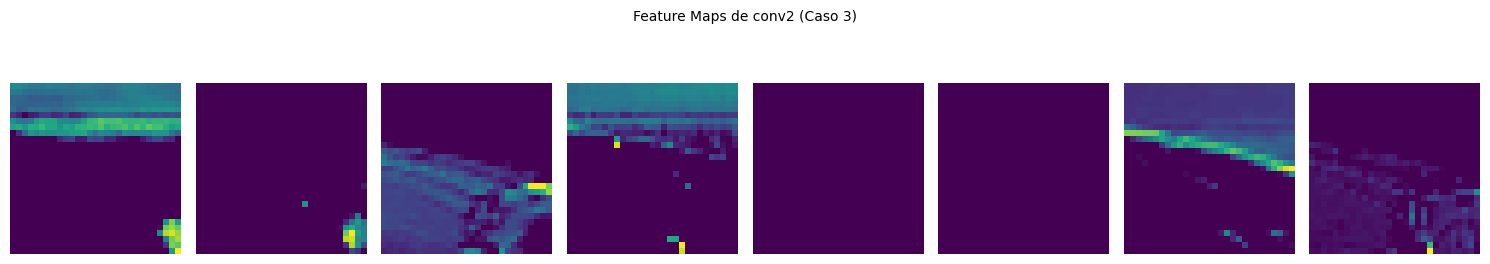

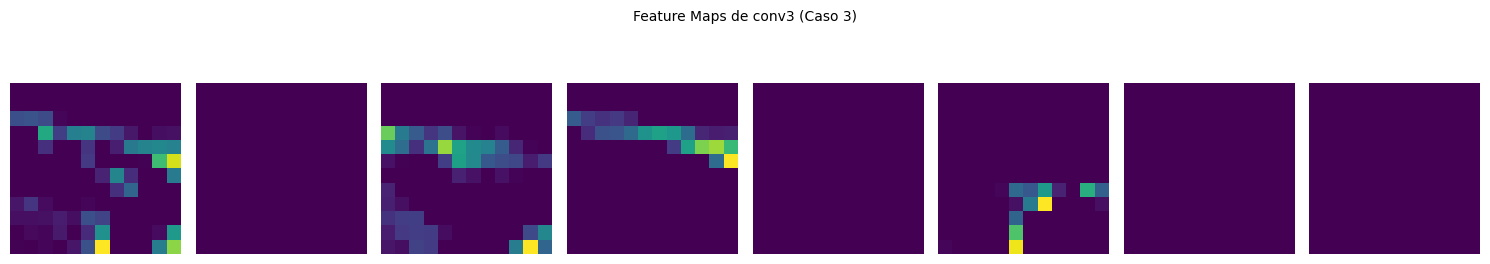

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Identificar el índice correspondiente a la clase 'sea'
idx_sea = nombre_clases.index('sea')

# 2. Filtrar las muestras reales de 'sea' que fueron clasificadas erróneamente
indices_sea_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_sea and pred != idx_sea:
        indices_sea_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de sea
muestras_sea_sel = indices_sea_erroneos[:3]
print(f"Se encontraron {len(indices_sea_erroneos)} predicciones erróneas para 'sea'.")
print(f"Visualizando Feature Maps para los índices de prueba: {muestras_sea_sel}\n")

# 3. Crear el modelo auxiliar de activaciones
modelo_activaciones = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("conv1").output,
        model.get_layer("conv2").output,
        model.get_layer("conv3").output
    ]
)

# 4. Iterar sobre las 3 imágenes seleccionadas para graficar sus activaciones
for num, idx in enumerate(muestras_sea_sel):
    # Preparar la imagen para el modelo
    img_raw = todas_las_imagenes[idx]
    img_tensor = tf.expand_dims(img_raw, axis=0)

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Mostrar la imagen original con su diagnóstico
    plt.figure(figsize=(4, 4))
    plt.imshow(img_raw.astype("uint8"))
    plt.title(f"Caso {num+1} | Real: {clase_real} -> Pred: {clase_pred}", color='red', fontsize=10, fontweight='bold')
    plt.axis("off")
    plt.show()

    # Obtener las activaciones de las capas convolucionales
    activaciones = modelo_activaciones.predict(img_tensor, verbose=0)

    # Mostrar mapas de características para conv1, conv2 y conv3
    for nombre_capa, activacion in zip(["conv1", "conv2", "conv3"], activaciones):
        mapas = activacion[0]
        cantidad = min(8, mapas.shape[-1])  # Mostrar hasta 8 filtros

        fig, axes = plt.subplots(1, cantidad, figsize=(15, 2.5))
        fig.suptitle(f"Feature Maps de {nombre_capa} (Caso {num+1})", fontsize=10, y=1.08)

        for i in range(cantidad):
            ax = axes[i] if cantidad > 1 else axes
            ax.imshow(mapas[:, :, i], cmap="viridis")
            ax.axis("off")

        plt.tight_layout()
        plt.show()
    print("-" * 80)

-  **Predicciones erroneas para forest:** Tomamos 3 ejemplos de predicciones de que se suponian que debian ser **forest** pero terminaron siendo reconocidas como **buildings** o **sea**


En el **caso 1** se obtuvo una mayor fuerza por las ramas/troncos, en la mayoría de los mapas (especialmente el 2, 3 y 4), los filtros responden con fuerza a las líneas rectas de los troncos y ramas que apuntan en distintas direcciones, estas líneas gruesas imitan los bordes de paredes o marcos, la    ausencia del color verde característico y texturas, como es una toma invernal o con tonos descoloridos en escala de grises/blancos, la red no detecta la textura típica de de un arbol comun (visible en el 5 y 8 mapa como bloques de brillo difuso).

En el **caso 2** hay una falta de activacion de los canales por color dominante rojo/otoñal, la tonalidad roja atípica de la imagen hace que varios mapas de características (especialmente el 1, 2, 6 y 7) queden prácticamente oscuros, de esta forma la red no logra extraer los rasgos de color e iluminación con los que habitualmente reconoce un bosque, tambien el patron de las texturas repetitivas y brillo oscuro, en los mapas que sí se activan (3, 4, 5 y 8), la densidad de los troncos delgados y las hojas genera una textura vertical y horizontal muy fina y homogénea que cubre toda la foto, este patrón de ondulaciones continuas y repetitivas se asemeja bastante a las vibraciones, ondas y reflejos de la superficie del agua en movimiento.

En el **caso 3** hay un fuerte activación de la línea del horizonte, en casi todos los mapas (destacando los 2.º, 3.º, 6.º, 7.º y 8.º), los filtros detectan una línea horizontal perfectamente recta y brillante justo en el centro de la imagen, esta división horizontal tajante es interpretada por el modelo como el borde superior de un muro o la línea de cornisa/techo de un edificio distante, la estructura en bloque en el centro, justo sobre esa línea horizontal central, hay un pequeño bloque claro en la imagen original (una edificación) que activa con brillo concentrado varios de los mapas (como el 2, 4 y 8), tambien cabe destacar que el desenfoque y ruina visual en la vegetación en primer plano generan una textura abierta y desordenada que el 5 mapa capta casi como un fondo oscuro mientras resalta las nubes del cielo.

Se encontraron 33 predicciones erróneas para 'forest'.
Visualizando Feature Maps para los índices de prueba: [448, 463, 475]



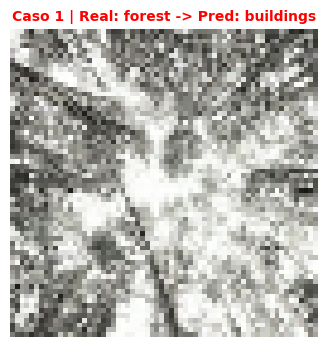

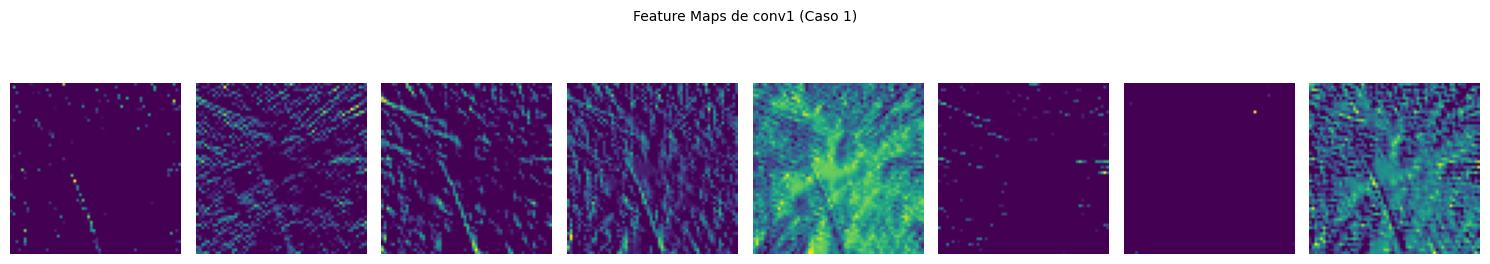

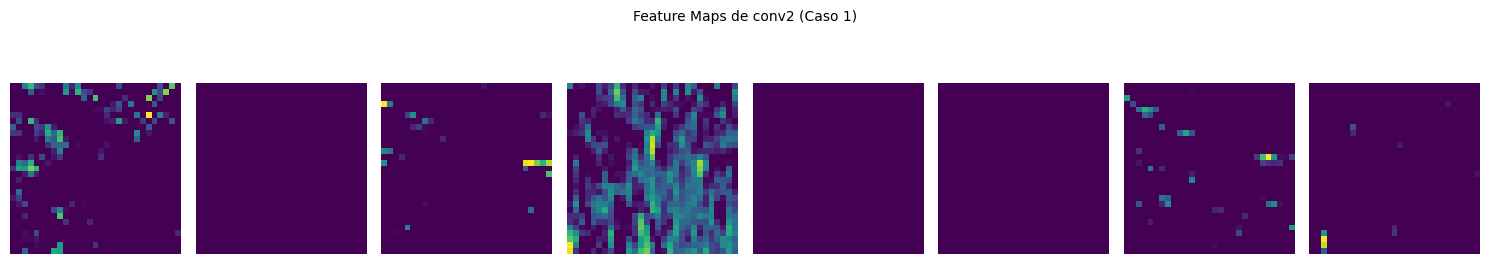

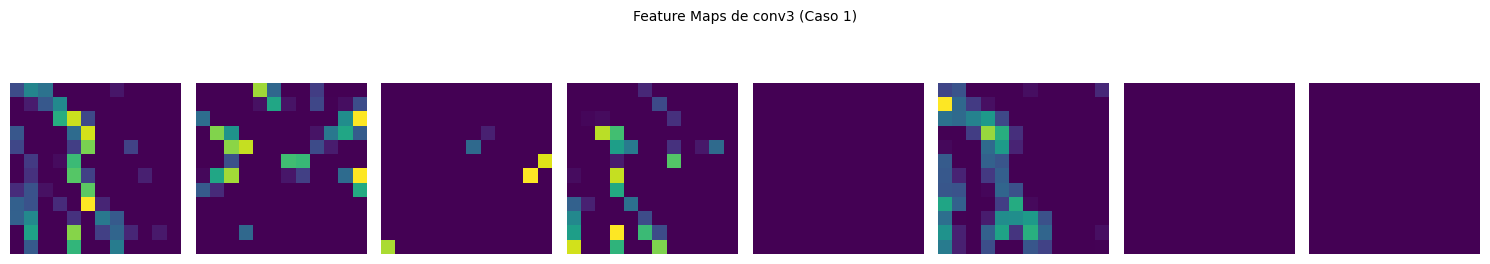

--------------------------------------------------------------------------------


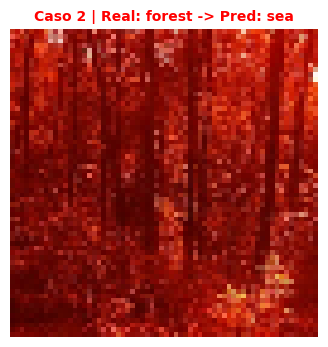

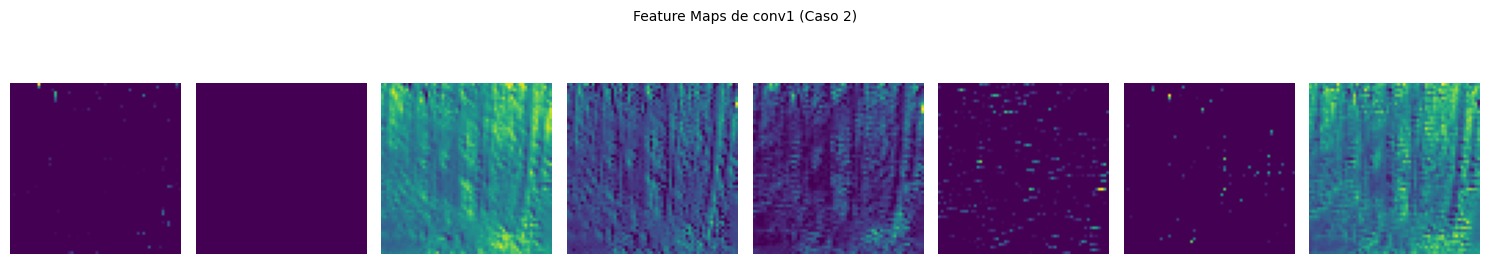

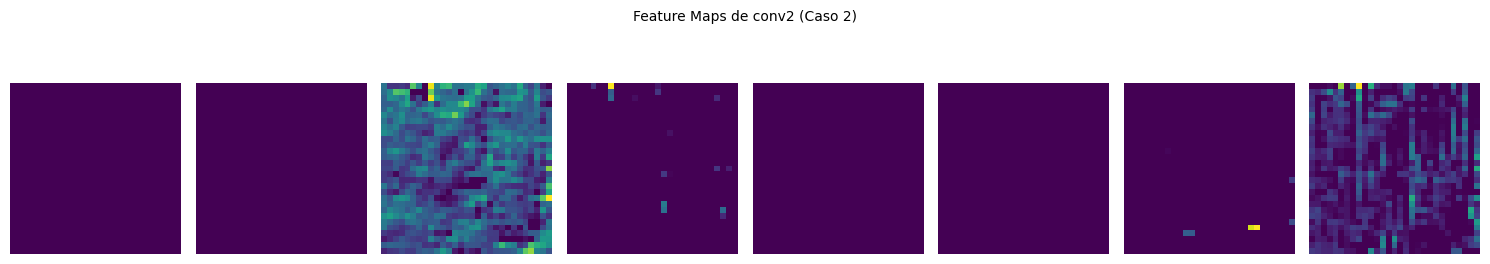

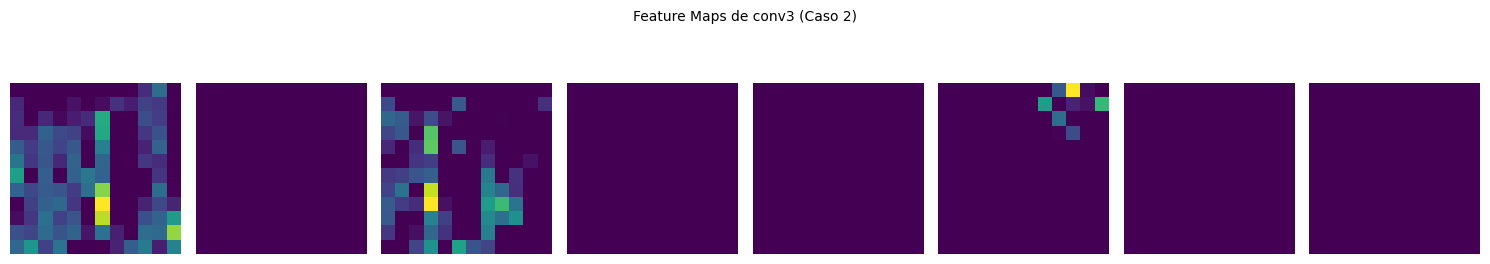

--------------------------------------------------------------------------------


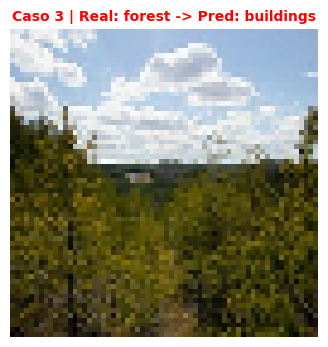

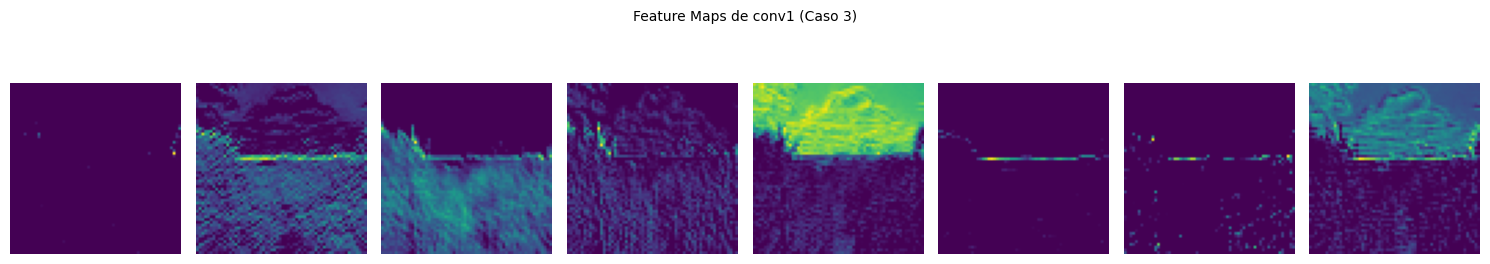

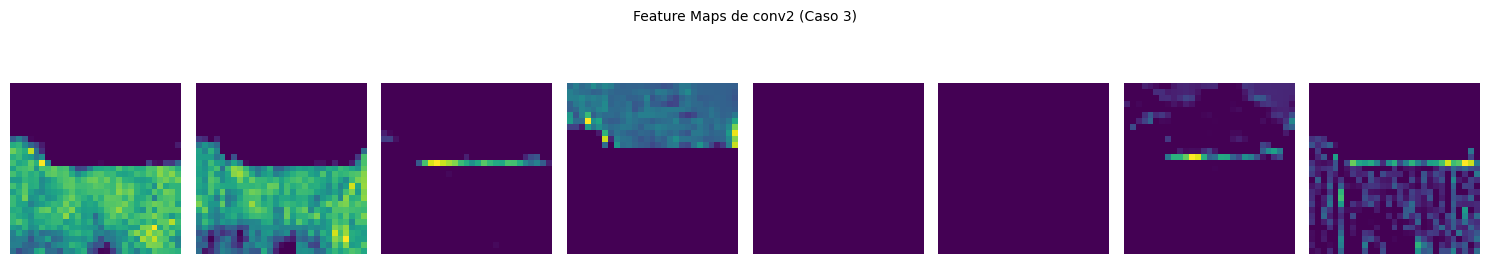

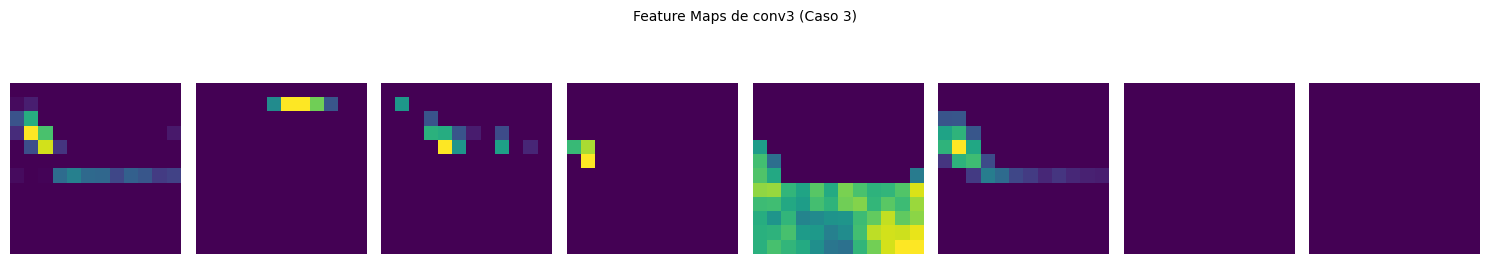

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Identificar el índice correspondiente a la clase 'forest'
idx_forest = nombre_clases.index('forest')

# 2. Filtrar las muestras reales de 'forest' que fueron clasificadas erróneamente
indices_forest_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_forest and pred != idx_forest:
        indices_forest_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de forest
muestras_forest_sel = indices_forest_erroneos[:3]
print(f"Se encontraron {len(indices_forest_erroneos)} predicciones erróneas para 'forest'.")
print(f"Visualizando Feature Maps para los índices de prueba: {muestras_forest_sel}\n")

# 3. Crear el modelo auxiliar de activaciones
modelo_activaciones = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("conv1").output,
        model.get_layer("conv2").output,
        model.get_layer("conv3").output
    ]
)

# 4. Iterar sobre las 3 imágenes seleccionadas para graficar sus activaciones
for num, idx in enumerate(muestras_forest_sel):
    # Preparar la imagen para el modelo
    img_raw = todas_las_imagenes[idx]
    img_tensor = tf.expand_dims(img_raw, axis=0)

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Mostrar la imagen original con su diagnóstico
    plt.figure(figsize=(4, 4))
    plt.imshow(img_raw.astype("uint8"))
    plt.title(f"Caso {num+1} | Real: {clase_real} -> Pred: {clase_pred}", color='red', fontsize=10, fontweight='bold')
    plt.axis("off")
    plt.show()

    # Obtener las activaciones de las capas convolucionales
    activaciones = modelo_activaciones.predict(img_tensor, verbose=0)

    # Mostrar mapas de características para conv1, conv2 y conv3
    for nombre_capa, activacion in zip(["conv1", "conv2", "conv3"], activaciones):
        mapas = activacion[0]
        cantidad = min(8, mapas.shape[-1])  # Mostrar hasta 8 filtros

        fig, axes = plt.subplots(1, cantidad, figsize=(15, 2.5))
        fig.suptitle(f"Feature Maps de {nombre_capa} (Caso {num+1})", fontsize=10, y=1.08)

        for i in range(cantidad):
            ax = axes[i] if cantidad > 1 else axes
            ax.imshow(mapas[:, :, i], cmap="viridis")
            ax.axis("off")

        plt.tight_layout()
        plt.show()
    print("-" * 80)

## **3.0 Interpretacion y comparacion de la Grad-Cam**

Se realizo una visualizacion mas detallada de la grad-cam que nos permita ver mas exactamente la superposicion del calor entre la imagen original y su mapa de calor, para entender en que partes de las fotos el modelo tuvo una mayor fijacion en los diferentes casos por cada clase en la que se equivoco con su prediccion.

**A continuacion el analizis de los 3 casos por cada clase que seleccionamos:**

Se identificaron 89 fallos para 'street'.
Generando Grad-CAM para los índices: [1421, 1434, 1438]



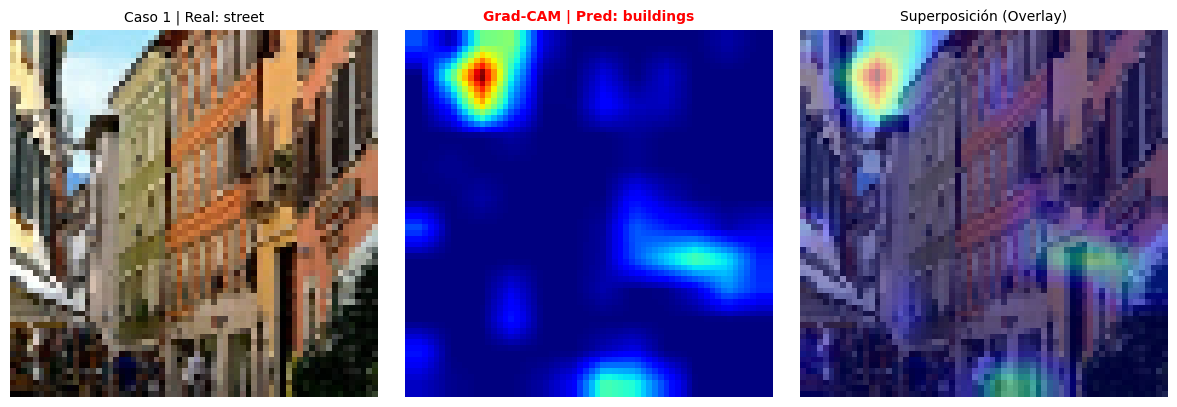

--------------------------------------------------------------------------------


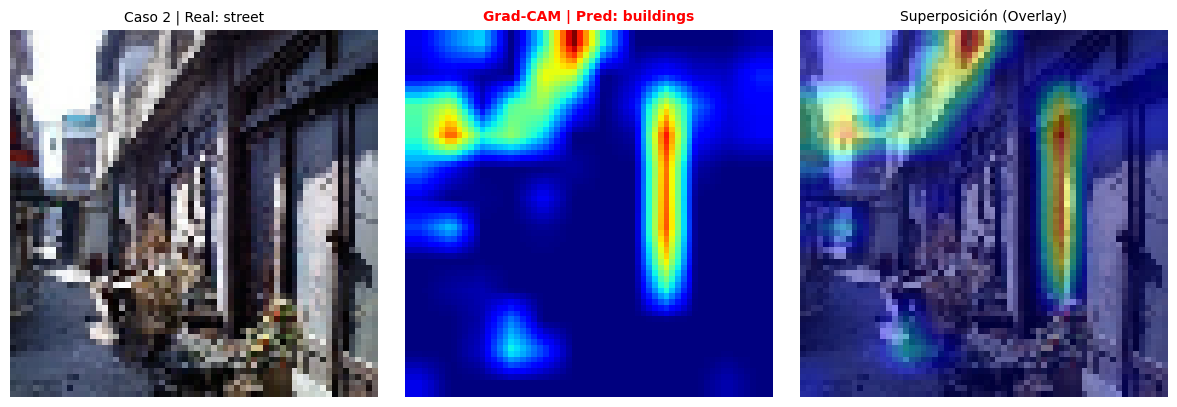

--------------------------------------------------------------------------------


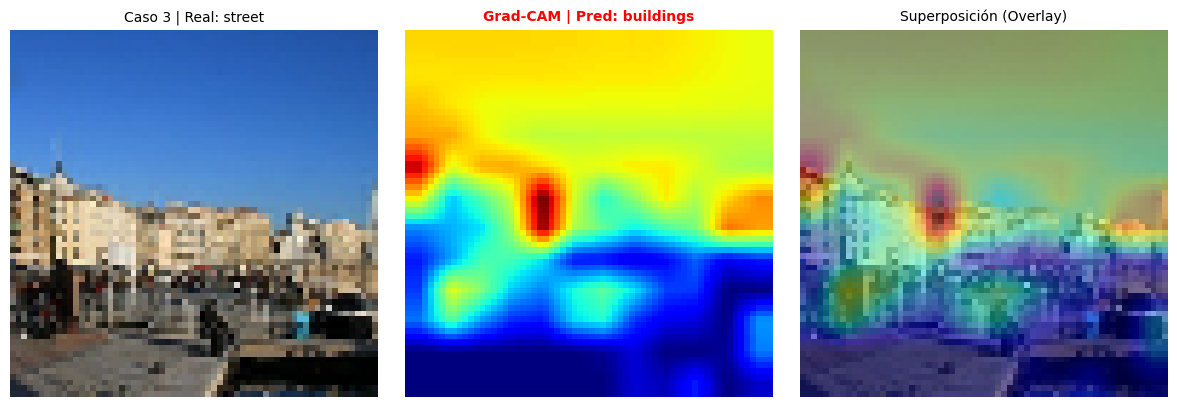

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Identificar el índice de la clase 'street'
idx_street = nombre_clases.index('street')

# 2. Filtrar los índices de 'street' que fueron mal clasificados
indices_street_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_street and pred != idx_street:
        indices_street_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de street
muestras_street_gradcam = indices_street_erroneos[:3]
print(f"Se identificaron {len(indices_street_erroneos)} fallos para 'street'.")
print(f"Generando Grad-CAM para los índices: {muestras_street_gradcam}\n")

# 3. Preparar el modelo auxiliar para Grad-CAM
last_conv = model.get_layer("conv3")
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[last_conv.output, model.outputs[0]]
)

# 4. Iterar y visualizar cada uno de los 3 casos
for num, idx in enumerate(muestras_street_gradcam):
    img_raw = todas_las_imagenes[idx] # Forma (64, 64, 3)
    img_tensor = tf.expand_dims(img_raw, axis=0) # Añadir dimensión de batch

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Calcular los gradientes con GradientTape
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_tensor)
        class_idx = tf.argmax(preds[0])
        loss = preds[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    # Promediar los gradientes
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Combinar los mapas ponderados
    cam = tf.reduce_sum(weights * conv_outputs[0], axis=-1)

    # Aplicar ReLU e interpolar el mapa a la resolución original (64x64)
    heatmap = tf.maximum(cam, 0)
    if tf.reduce_max(heatmap) > 0:
        heatmap /= tf.reduce_max(heatmap)

    heatmap_resized = tf.image.resize(heatmap[..., tf.newaxis], (64, 64))
    heatmap_resized = tf.squeeze(heatmap_resized).numpy()

    # Preparar la imagen para mostrar (rango 0 a 1)
    img_display = np.clip(img_raw / 255.0, 0.0, 1.0)

    # Graficar
    plt.figure(figsize=(12, 4))

    # Subplot 1: Imagen Original
    plt.subplot(1, 3, 1)
    plt.imshow(img_display)
    plt.title(f"Caso {num+1} | Real: {clase_real}", fontsize=10)
    plt.axis("off")

    # Subplot 2: Mapa de Calor Grad-CAM
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title(f"Grad-CAM | Pred: {clase_pred}", fontsize=10, color='red', fontweight='bold')
    plt.axis("off")

    # Subplot 3: Superposición
    plt.subplot(1, 3, 3)
    plt.imshow(img_display)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
    plt.title("Superposición (Overlay)", fontsize=10)
    plt.axis("off")

    plt.tight_layout()
    plt.show()
    print("-" * 80)

En el **caso 1** la atención estuvo principalmente en la cornisa y el cielo superior, la zona roja de máxima activación se concentra fuertemente en la esquina superior izquierda, sobre el borde superior del edificio y la pequeña porción de cielo visible, el modelo ignoró completamente el pavimento inferior y el flujo de la calle, al basar su decisión en el remate superior de las fachadas y los bordes rectos contra el cielo, priorizó la presencia de estructuras arquitectónicas verticales, prediciendo buildings.

En el **caso 2** la atención estuvo en los pilares verticales y los marcos la zona cálida principal (roja/amarilla) se ubica en una franja vertical alineada con los marcos de la puerta/ventana a la derecha, además de un foco secundario en la pared lateral izquierda la red no presta atención al pasaje o suelo del callejón, en su lugar, se enfoca exclusivamente en elementos estructurales individuales como marcos de puertas y columnas, lo que la lleva a concluir que la escena representa buildings.

En el **caso 3** la atención estuvo en la línea continua de fachadas, el mapa de calor muestra un punto rojo intenso en el centro sobre el bloque de departamentos, extendiéndose en tonos amarillos a lo largo del límite superior de toda la línea de edificios, la mitad inferior (el suelo y las personas a nivel de calle) queda en tonos fríos/azules, demostrando que el modelo no consideró el espacio público inferior, la predicción buildings se debe a la atención dominante en la masa continua de paredes y techos que ocupan el centro y la parte superior de la escena.

Se identificaron 72 fallos para 'buildings'.
Generando Grad-CAM para los índices: [7, 20, 22]



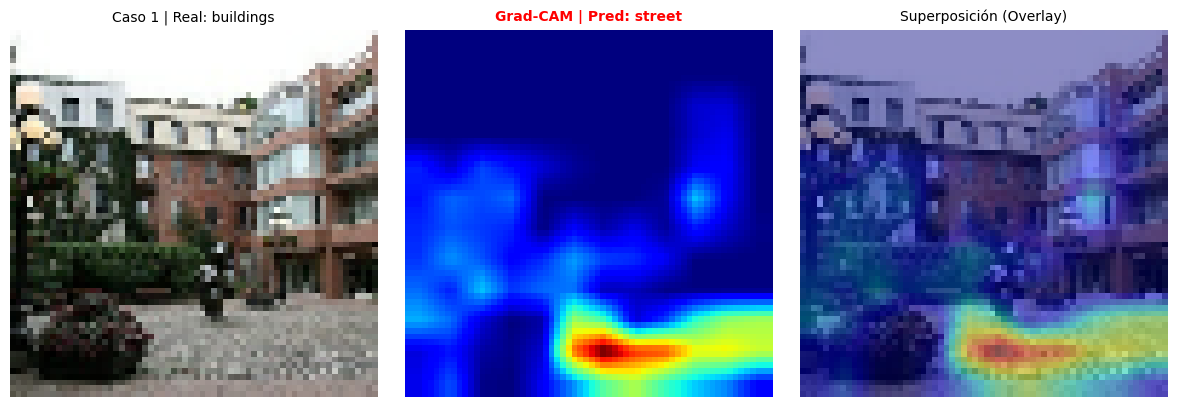

--------------------------------------------------------------------------------


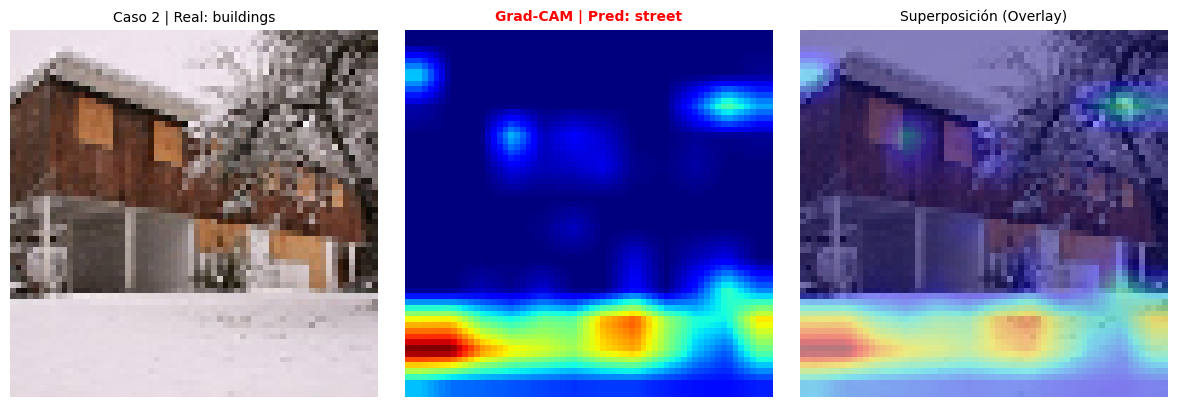

--------------------------------------------------------------------------------


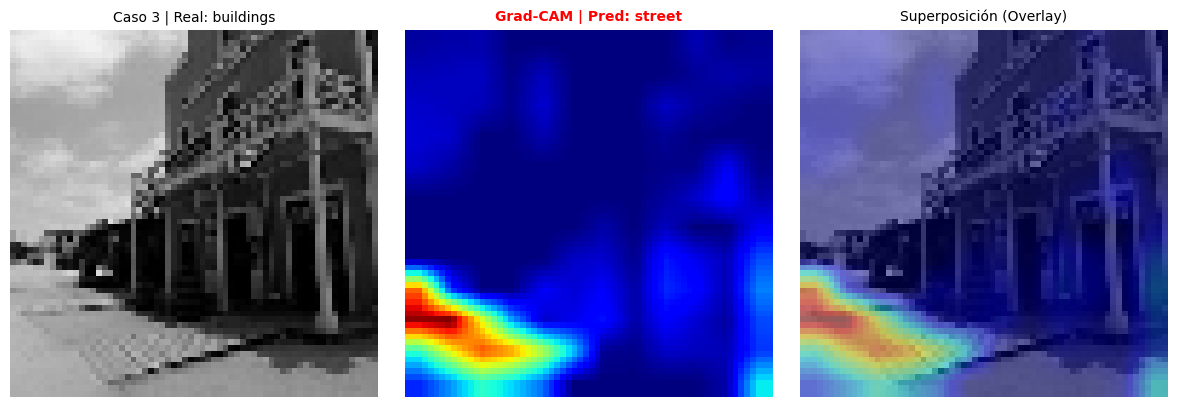

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Identificar el índice de la clase 'buildings'
idx_buildings = nombre_clases.index('buildings')

# 2. Filtrar los índices de 'buildings' que fueron mal clasificados
indices_buildings_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_buildings and pred != idx_buildings:
        indices_buildings_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de buildings
muestras_buildings_gradcam = indices_buildings_erroneos[:3]
print(f"Se identificaron {len(indices_buildings_erroneos)} fallos para 'buildings'.")
print(f"Generando Grad-CAM para los índices: {muestras_buildings_gradcam}\n")

# 3. Preparar el modelo auxiliar para Grad-CAM
last_conv = model.get_layer("conv3")
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[last_conv.output, model.outputs[0]]
)

# 4. Iterar y visualizar cada uno de los 3 casos
for num, idx in enumerate(muestras_buildings_gradcam):
    img_raw = todas_las_imagenes[idx] # Forma (64, 64, 3)
    img_tensor = tf.expand_dims(img_raw, axis=0) # Añadir dimensión de batch

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Calcular los gradientes con GradientTape
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_tensor)
        class_idx = tf.argmax(preds[0])
        loss = preds[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    # Promediar los gradientes
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Combinar los mapas ponderados
    cam = tf.reduce_sum(weights * conv_outputs[0], axis=-1)

    # Aplicar ReLU e interpolar el mapa a la resolución original (64x64)
    heatmap = tf.maximum(cam, 0)
    if tf.reduce_max(heatmap) > 0:
        heatmap /= tf.reduce_max(heatmap)

    heatmap_resized = tf.image.resize(heatmap[..., tf.newaxis], (64, 64))
    heatmap_resized = tf.squeeze(heatmap_resized).numpy()

    # Preparar la imagen para mostrar (rango 0 a 1)
    img_display = np.clip(img_raw / 255.0, 0.0, 1.0)

    # Graficar
    plt.figure(figsize=(12, 4))

    # Subplot 1: Imagen Original
    plt.subplot(1, 3, 1)
    plt.imshow(img_display)
    plt.title(f"Caso {num+1} | Real: {clase_real}", fontsize=10)
    plt.axis("off")

    # Subplot 2: Mapa de Calor Grad-CAM
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title(f"Grad-CAM | Pred: {clase_pred}", fontsize=10, color='red', fontweight='bold')
    plt.axis("off")

    # Subplot 3: Superposición
    plt.subplot(1, 3, 3)
    plt.imshow(img_display)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
    plt.title("Superposición (Overlay)", fontsize=10)
    plt.axis("off")

    plt.tight_layout()
    plt.show()
    print("-" * 80)

En el **caso 1** tuvo una mayor atención en el pavimento, la zona cálida (roja y amarilla) se sitúa directamente sobre el suelo adoquinado en la parte inferior derecha de la escena, el modelo ignoró casi por completo las fachadas y ventanas de los edificios del fondo, al fijar su atención exclusivamente en la textura del piso plano, interpretó ese espacio abierto a nivel de suelo como una vía o calle pública, prediciendo street

En el **caso 2** tuvo una mayor atención en la franja de nieve, la zona roja más intensa forma una franja horizontal continua a lo largo de toda la capa de nieve inferior, las paredes de madera y la fachada de la casa quedaron completamente en tonos fríos (azules), la red asoció esa amplia superficie llana e ininterrumpida de nieve con una calzada o calle abierta, lo que derivó en la predicción errónea de street.   

En el **caso 3** tuvo una atención en la acera y perspectiva, la activación principal (rojo brillante) se localiza en la esquina inferior izquierda, cubriendo la acera y el plano inclinado del suelo que se extiende hacia el fondo, la arquitectura y los detalles del pórtico del edificio quedaron invisibilizados para la red, al enfocar toda su atención en la acera y las líneas de fuga del camino lateral, el modelo interpretó la imagen como un paso peatonal o calle (street).

Se identificaron 51 fallos para 'sea'.
Generando Grad-CAM para los índices: [912, 923, 937]



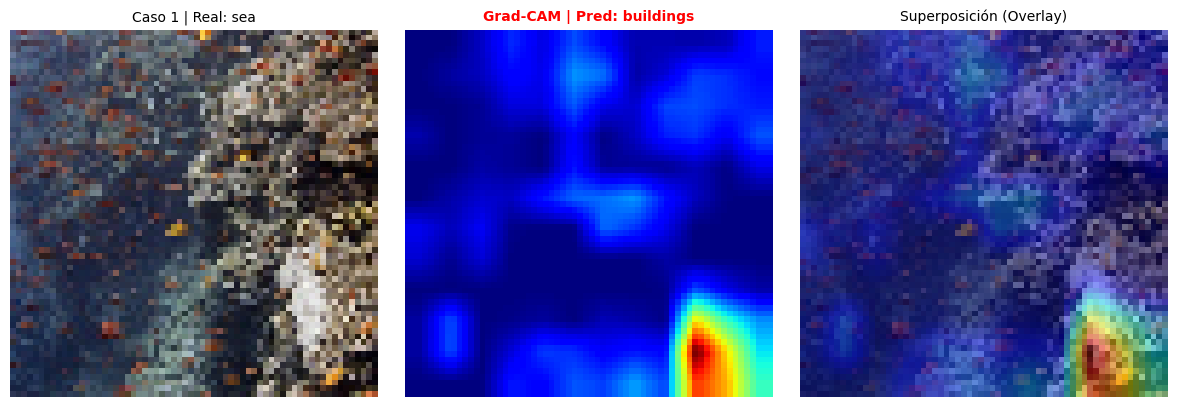

--------------------------------------------------------------------------------


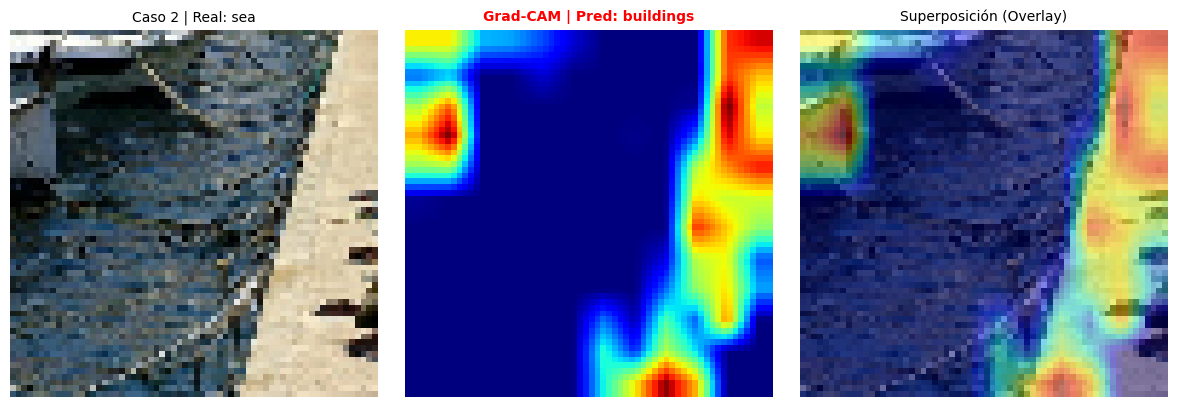

--------------------------------------------------------------------------------


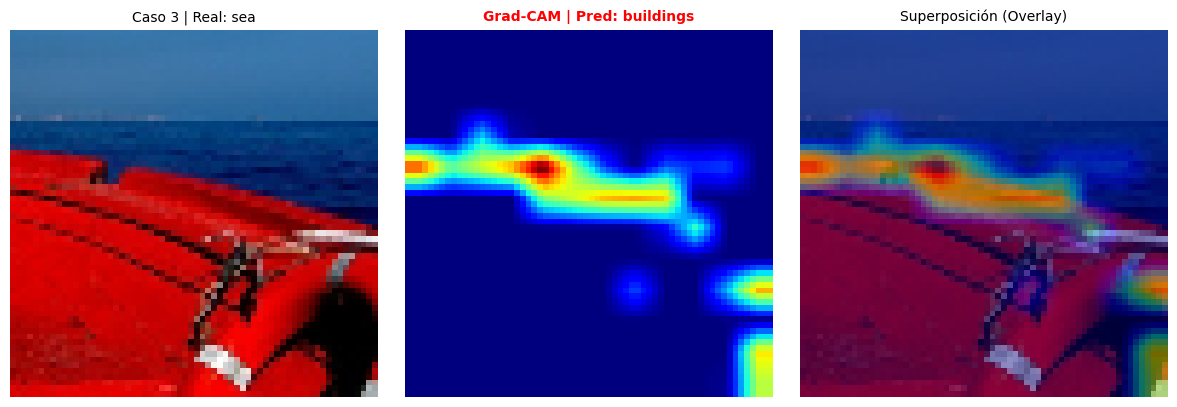

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Identificar el índice de la clase 'sea'
idx_sea = nombre_clases.index('sea')

# 2. Filtrar los índices de 'sea' que fueron mal clasificados
indices_sea_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_sea and pred != idx_sea:
        indices_sea_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de sea
muestras_sea_gradcam = indices_sea_erroneos[:3]
print(f"Se identificaron {len(indices_sea_erroneos)} fallos para 'sea'.")
print(f"Generando Grad-CAM para los índices: {muestras_sea_gradcam}\n")

# 3. Preparar el modelo auxiliar para Grad-CAM
last_conv = model.get_layer("conv3")
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[last_conv.output, model.outputs[0]]
)

# 4. Iterar y visualizar cada uno de los 3 casos
for num, idx in enumerate(muestras_sea_gradcam):
    img_raw = todas_las_imagenes[idx] # Forma (64, 64, 3)
    img_tensor = tf.expand_dims(img_raw, axis=0) # Añadir dimensión de batch

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Calcular los gradientes con GradientTape
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_tensor)
        class_idx = tf.argmax(preds[0])
        loss = preds[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    # Promediar los gradientes
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Combinar los mapas ponderados
    cam = tf.reduce_sum(weights * conv_outputs[0], axis=-1)

    # Aplicar ReLU e interpolar el mapa a la resolución original (64x64)
    heatmap = tf.maximum(cam, 0)
    if tf.reduce_max(heatmap) > 0:
        heatmap /= tf.reduce_max(heatmap)

    heatmap_resized = tf.image.resize(heatmap[..., tf.newaxis], (64, 64))
    heatmap_resized = tf.squeeze(heatmap_resized).numpy()

    # Preparar la imagen para mostrar (rango 0 a 1)
    img_display = np.clip(img_raw / 255.0, 0.0, 1.0)

    # Graficar
    plt.figure(figsize=(12, 4))

    # Subplot 1: Imagen Original
    plt.subplot(1, 3, 1)
    plt.imshow(img_display)
    plt.title(f"Caso {num+1} | Real: {clase_real}", fontsize=10)
    plt.axis("off")

    # Subplot 2: Mapa de Calor Grad-CAM
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title(f"Grad-CAM | Pred: {clase_pred}", fontsize=10, color='red', fontweight='bold')
    plt.axis("off")

    # Subplot 3: Superposición
    plt.subplot(1, 3, 3)
    plt.imshow(img_display)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
    plt.title("Superposición (Overlay)", fontsize=10)
    plt.axis("off")

    plt.tight_layout()
    plt.show()
    print("-" * 80)

En el **caso 1** tuvo una mayor atención en la textura rocosa inferior, la zona roja de máxima activación se concentra exclusivamente en la esquina inferior derecha, cubriendo la parte baja de las rocas y sus sombras el agua de la mitad izquierda quedó totalmente en azul (sin atención), al enfocar su decisión en los bloques de piedra con texturas rugosas e irregulares, el modelo interpretó esa formación sólida como la fachada o cimientos de piedra de un edificio, prediciendo buildings.   

En el **caso 2** tuvo una mayor atención en estructuras rígidas (muelle y bordes), las zonas cálidas (rojas y amarillas) cubren toda la franja vertical derecha del muelle de piedra, además de un foco secundario en la embarcación/estructura de la izquierda, la superficie del agua central permanece en tonos fríos e ignorada. El modelo centró su atención en los elementos construidos por el hombre (el muro recto de concreto/piedra), clasificando la imagen como buildings.   

En el **caso 3** tuvo una mayor atención en el borde horizontal del bote y el horizonte, la activación roja más intensa forma una barra horizontal justo en la unión del bote con el agua, extendiéndose a lo largo del borde de la cubierta, el mar abierto al fondo no recibió atención relevante, la red interpretó la línea horizontal recta y la gran masa estructurada roja del bote como el tejado, cornisa o pared lateral de una edificación, derivando en la predicción errónea de buildings.

Se identificaron 33 fallos para 'forest'.
Generando Grad-CAM para los índices: [448, 463, 475]



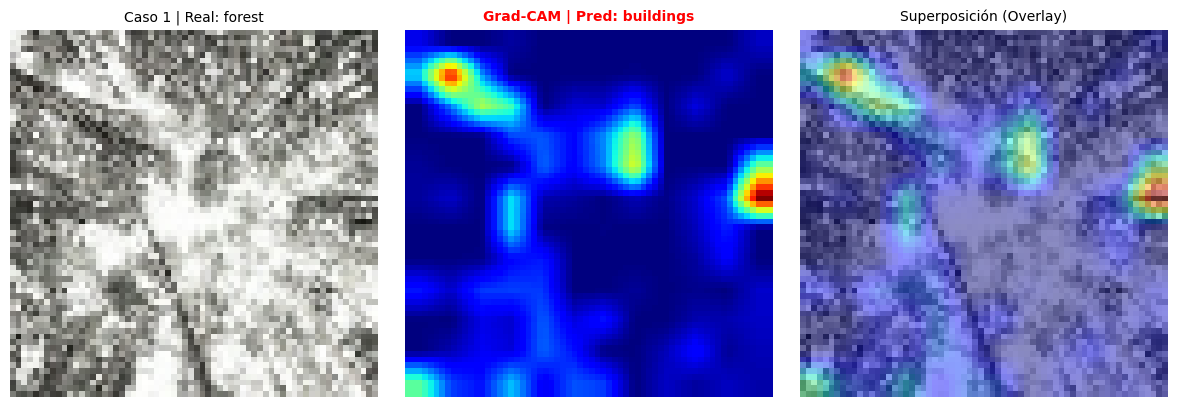

--------------------------------------------------------------------------------


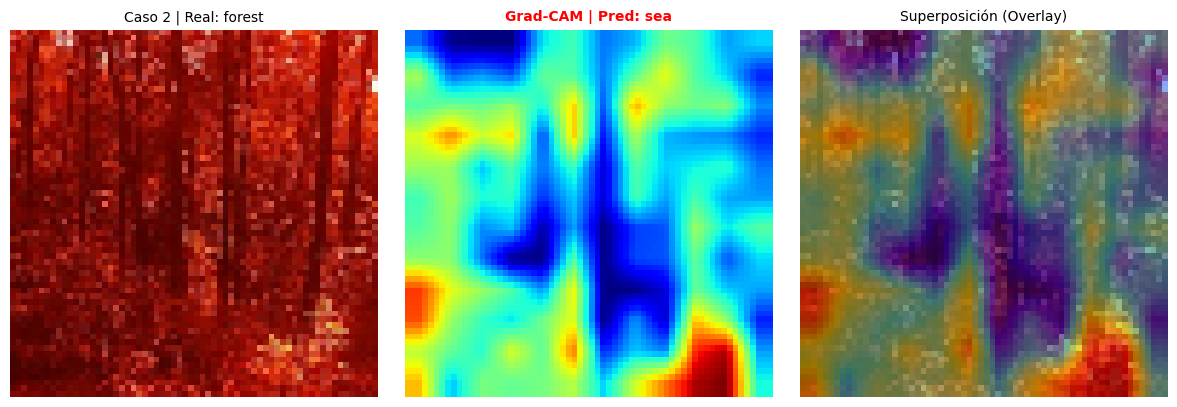

--------------------------------------------------------------------------------


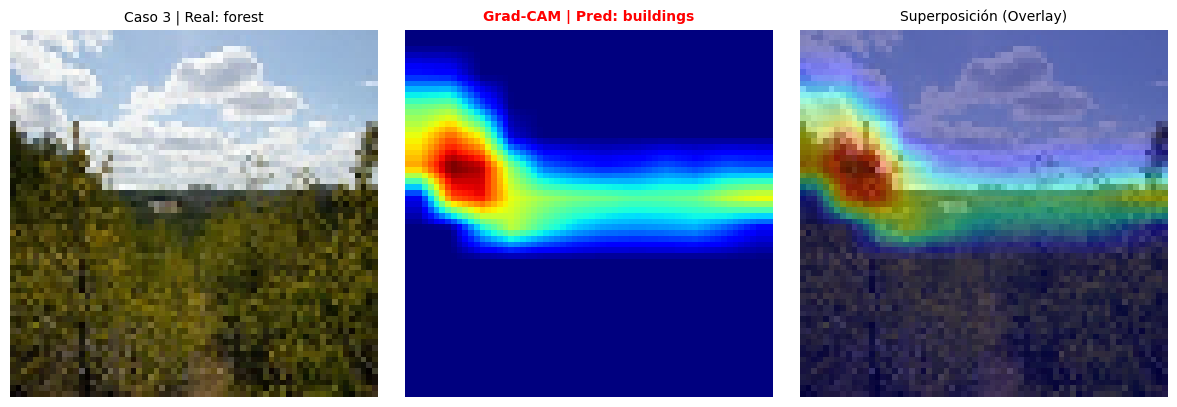

--------------------------------------------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Identificar el índice de la clase 'forest'
idx_forest = nombre_clases.index('forest')

# 2. Filtrar los índices de 'forest' que fueron mal clasificados
indices_forest_erroneos = []
for idx in range(len(todas_las_etiquetas)):
    real = todas_las_etiquetas[idx]
    pred = todas_las_predicciones[idx]
    if real == idx_forest and pred != idx_forest:
        indices_forest_erroneos.append(idx)

# Seleccionar las primeras 3 muestras incorrectas de forest
muestras_forest_gradcam = indices_forest_erroneos[:3]
print(f"Se identificaron {len(indices_forest_erroneos)} fallos para 'forest'.")
print(f"Generando Grad-CAM para los índices: {muestras_forest_gradcam}\n")

# 3. Preparar el modelo auxiliar para Grad-CAM
last_conv = model.get_layer("conv3")
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[last_conv.output, model.outputs[0]]
)

# 4. Iterar y visualizar cada uno de los 3 casos
for num, idx in enumerate(muestras_forest_gradcam):
    img_raw = todas_las_imagenes[idx] # Forma (64, 64, 3)
    img_tensor = tf.expand_dims(img_raw, axis=0) # Añadir dimensión de batch

    clase_real = nombre_clases[todas_las_etiquetas[idx]]
    clase_pred = nombre_clases[todas_las_predicciones[idx]]

    # Calcular los gradientes con GradientTape
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_tensor)
        class_idx = tf.argmax(preds[0])
        loss = preds[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    # Promediar los gradientes
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Combinar los mapas ponderados
    cam = tf.reduce_sum(weights * conv_outputs[0], axis=-1)

    # Aplicar ReLU e interpolar el mapa a la resolución original (64x64)
    heatmap = tf.maximum(cam, 0)
    if tf.reduce_max(heatmap) > 0:
        heatmap /= tf.reduce_max(heatmap)

    heatmap_resized = tf.image.resize(heatmap[..., tf.newaxis], (64, 64))
    heatmap_resized = tf.squeeze(heatmap_resized).numpy()

    # Preparar la imagen para mostrar (rango 0 a 1)
    img_display = np.clip(img_raw / 255.0, 0.0, 1.0)

    # Graficar
    plt.figure(figsize=(12, 4))

    # Subplot 1: Imagen Original
    plt.subplot(1, 3, 1)
    plt.imshow(img_display)
    plt.title(f"Caso {num+1} | Real: {clase_real}", fontsize=10)
    plt.axis("off")

    # Subplot 2: Mapa de Calor Grad-CAM
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title(f"Grad-CAM | Pred: {clase_pred}", fontsize=10, color='red', fontweight='bold')
    plt.axis("off")

    # Subplot 3: Superposición
    plt.subplot(1, 3, 3)
    plt.imshow(img_display)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
    plt.title("Superposición (Overlay)", fontsize=10)
    plt.axis("off")

    plt.tight_layout()
    plt.show()
    print("-" * 80)

En el **caso 1** la atención se fue en cruces de líneas y bordes dispersos, las zonas de máxima activación (rojas y amarillas) se concentran en la esquina superior izquierda y en el margen derecho, directamente sobre la convergencia de ramas y troncos secos en perspectiva, el centro claro e iluminado no atrajo la atención del modelo. En su lugar, basó su decisión en los puntos donde se cruzan las líneas rectas del ramaje, interpretando esa estructura angular como vértices o marcos de ventanas/fachadas de un edificio (buildings).   

En el **caso 2** la atención estuvo en zonas difusas laterales e inferiores, la activación cálida más intensa (roja) se localiza en la esquina inferior derecha, extendiéndose en tonos cian y amarillos por casi toda la superficie de la imagen en abanico, el modelo ignoró la alineación vertical de los troncos centrales (que quedan en una franja azul e inactiva), al fijarse en las áreas donde las hojas forman una textura continua, brillante e indiferenciada a lo largo del suelo y laterales, interpretó ese patrón como el reflejo o vaivén de la superficie del agua, clasificándolo como mar (sea).

En el **caso 3** la atención estuvo en la franja del horizonte y árbol lateral, la zona de máxima intensidad (roja profunda) se ubica sobre la copa del árbol de la izquierda, proyectando una banda continua de color verde/amarillo a lo largo de toda la línea del horizonte, toda la vegetación densa del primer plano inferior quedó ignorada en azul, la red se concentró en el perfil delimitado contra el cielo y la línea horizontal central, interpretando ese remate plano junto al bloque oscuro de la izquierda como la silueta del techo o cornisa de una estructura urbana (buildings).

**Conclusion en base a lo analizado:** Al final del analizis de todos los casos nos dimos cuenta que en las prediccion el principal factor que afecto las predicciones de nuestro modelo, fueron la confusion de las texturas mas dificiles de analizar y las lineas perfectas, uno de los principales cambios que se añadirian en siguientes modelos para el reconocimiento de las imagenes, seria añadir una capa convolucional que nos permita analizar mas a fondos las texturas para asi poder tener una mayor identificacion y precision al momento de la prediccion

### **3.1 Desempeño Alcanzado por el Modelo**

El modelo CNN que diseñamos pudo conseguir un buen rendimiento general en cuanto a los objetivos mencionados del $85$% de **recall** y una prediccion esperada de las metricas f1-score y precision por encima del $82$% y $80$%, las maximas equivocaciones que pudimos observar fueron en las clases **street y building**, pero en general el modelo pudo generalizar de la manera esperaba obteniendo muy buenos resultados.

### **3.2 Principales Decisiones de Diseño**

Las decisiones clave incluyeron:
-   **Capas de Regularización (`Dropout`)**: La capa `Dropout(0.5)` que añadimos fue para desconectar aleatoriamente neuronas durante el entrenamiento, lo que forzo al modelo a aprender características más robustas evitando de esta manera el sobreajuste.
-   **`EarlyStopping`**: La detención temprana basada en la pérdida de validación (`val_loss`) fue clave para encontrar el punto óptimo de entrenamiento basandose en el mejor valor de la loss, en la que si notaba con un nivel de paciencia (en nuestro caso 5) este descartaba las epocas en las comenzo a sobreajustarse, seleccionando los mejores pesos del modelo.


## **3.3 Fortalezas y Limitaciones Observadas**

**Fortalezas:**

-  **Alto Rendimiento y Balance Metodológico:** El modelo logró una excelente capacidad de generalización en las 4 clases que seleccionamos (buildings, forest, sea, street), alcanzando una precisión de validación ($\text{Val Accuracy}$) de $\ 88\%$ y un $\text{Val Recall}$ de $\ 87.8\%$, superando nuestra meta mínima del $85\%$.

-  **Control Efectivo del Sobreajuste (Overfitting):** La integración de un esquema de regularización mediante Dropout(0.5) en la capa densa y el uso del EarlyStopping (con restauración de pesos en el punto mínimo de val_loss) evitaron la memorización del conjunto de entrenamiento.

-  **Explicabilidad e Interpretabilidad (XAI):** La implementación de Grad-CAM sobre la última capa convolucional (conv3) permitió verificar visualmente que la red concentra sus decisiones en patrones relevantes de cada clase (por ejemplo, bordes arquitectónicos en buildings), descartando elementos innecesarios como el cielo o el fondo.

-  **Garantía de Reproducibilidad:** Todo el pipeline de preparación de datos, particionado (80/20) y entrenamiento se diseñó bajo la fijación de la semilla (SEED = 42).

**Limitaciones:**

-  **Resolución Espacial Restringida:** El redimensionamiento de las imágenes a $64 \times 64$ píxeles, aunque optimiza el costo computacional y la memoria, elimina detalles finos y texturas de bajo nivel que podrían ser clave para diferenciar imagenes mas complejas.

-  **Sensibilidad a Patrones Geométricos Complejos:** Al depender principalmente de la detección de aristas y estructuras (como se observó en Grad-CAM), el modelo puede presentar confusiones en imágenes urbanas complejas donde se camuflan elementos de street y buildings.

## **3.4 Posibles Mejoras Futuras**

Para cambios futuros del proyecto, proponemos las siguientes líneas de desarrollo con la finalidad de superar las limitaciones actuales y aumentar la capacidad de generalización del modelo:

-  **Implementación de Transfer Learning y Fine-Tuning:** Sustituir la arquitectura secuencial por modelos de vanguardia pre-entrenados en ImageNet (tales como ResNet50, EfficientNetB0 o MobileNetV2). Ajustar las capas superiores (fine-tuning) permitiría aprovechar extractores de características más profundos, incrementando la precisión en las 4 clases de paisajes.

-  **Aumento de la Resolución de Entrada:** Incrementar la dimensión de entrada desde $64 \times 64$ hacia $128 \times 128$ o $224 \times 224$ píxeles. Esto proporcionaría mayor detalle espacial y fino a los bloques convolucionales, facilitando la distinción en escenarios con alta densidad de textura (e.g., entre la vegetación de forest y las líneas urbanas de street).

-  **Técnicas Avanzadas de Data Augmentation:** Ampliar el pipeline de aumento de datos agregando transformaciones avanzadas como variaciones de brillo/contraste cromático, pequeños cambios de perspectiva y técnicas de regularización espacial como Mixup o CutMix, reduciendo aún más la dependencia de la red hacia patrones de iluminación específicos.

-  **Optimización Sistemática de Hiperparámetros:** Emplear estrategias de búsqueda estructurada (como Optuna, Random Search o Grid Search) para sintonizar automáticamente la tasa de aprendizaje (learning rate), el tamaño de lote (batch size), la tasa de dropout en las capas densas y la paciencia del EarlyStopping.

-  **Análisis de Errores y Explicabilidad Guiada (XAI Avanzado):** Utilizar las visualizaciones de Grad-CAM no solo para validación, sino como herramienta de diagnóstico para aislar falsos positivos/negativos en el dataset de test independiente. Esto facilitará identificar subgrupos de imágenes ambiguas y aplicar filtros o limpieza de datos dirigida.